# 7.0 · Árboles de Decisión (CRISP-DM Fase 4 · Modelado) — Proyecto JobPath

> ## Pregunta central del cuaderno
> **¿El perfil de un oficio separa a las personas que lo repiten de las que lo ejercen por primera vez?**

---

### Marco Metodológico (CRISP-DM Fase 4 · Primera parte de la serie `7.0`, `7.1`, `7.2`)

Este cuaderno abre la serie de modelado supervisado interpretativo del proyecto **JobPath** (`7.0_arbol_decision.ipynb` $\rightarrow$ `7.1_naive_bayes.ipynb` $\rightarrow$ `7.2_knn.ipynb`). Aquí construimos y evaluamos **únicamente los Árboles de Decisión (`7.0`)**.

No se entrena un árbol único mezclado para la pregunta central; en su lugar, respondemos la pregunta desde **tres ángulos complementarios**, entrenando tres árboles independientes que mantienen **exactamente la misma variable objetivo `y` (`reincide`), la misma partición `train/test` agrupada por persona (`resume_id`, `random_state=42`) y el mismo límite de profundidad (`max_depth=4`)**, cambiando únicamente el bloque de variables explicativas `X`:

| Árbol | Sub-pregunta de negocio | Bloque de variables `X` (sin mezclar bloques) |
|---|---|---|
| **1 · ISCO** | *¿Qué es el oficio?* | Información de Grandes Grupos ocupacionales ISCO-08 a 1 dígito (`isco_major_0` .. `isco_major_9`, dummies 0/1). Se auditan en bitácora las variantes a 2 dígitos y Top-50 a 4 dígitos. |
| **2 · Nivel educativo** | *¿Quién ejerce el oficio?* | Nivel educativo formal en escala ordinal (`nivel_educativo_ord`: `0..4`) + bandera explícita de ausencia informativa (`educacion_no_reportada`: `0/1`, mecanismo MNAR). |
| **3 · Competencias** | *¿Qué exige el oficio?* | Conteos en unidades reales ESCO sin escalar (`n_skills_essential`, `n_skills_competence`, `n_skills_knowledge`) y proporciones internas del bloque evaluadas en validación cruzada. |

---

### Qué recibe este cuaderno y qué entrega a los siguientes

1. **Insumos que recibe (en modo solo lectura, trabajando sobre `.copy()` en RAM)**:
   - **Versión A (por defecto para los árboles)**: `data/03_processed/empleos_unificado_limpio.csv` (`1,871,014` registros de `355,308` personas), **CON outliers y SIN escalar**, porque los árboles de decisión particionan por orden (umbrales invariantes a transformaciones monótonas) y sus reglas deben leerse en **unidades reales del dominio** (por ejemplo, *"19 o más competencias prácticas"* en lugar de puntajes $z$ o rangos intercuartílicos). No se utiliza la matriz `X` escalada de `data/04_transformed/`.
   - **Versión B (para la prueba de sensibilidad del bloque final)**: `data/03_processed/empleos_limpio_con_competencias_sin_outliers.csv` (winsorizada por IQR $k=1.5$).
   - **Partición por persona (`resume_id`)**: `GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)` documentada en `reports/eda_jobpath/tables/split_map_resume_id.csv` y `data/04_transformed/`.
   - **Techo empírico de referencia**: resultados de los modelos multivariados completos de `6.0_modelado_fase4_jobpath.ipynb` (`reports/modelado_jobpath/tables/resultados_test_ab.csv`), donde la Regresión Logística Regularizada con 2,981 variables alcanzó `F1 = 0.5321` y `HistGradientBoosting` con 14 variables densas alcanzó `F1 = 0.5151`.

2. **Nota obligatoria sobre el Acta del Proyecto (`1.0_comprension_negocio.md`)**:
   - El documento fundacional `notebooks/refactor/1.0_comprension_negocio.md` declaró originalmente que el proyecto tenía una orientación **no supervisada** (agrupamiento de trayectorias y matrices de transición) y que no existía una columna objetivo única.
   - La variable objetivo binaria **`reincide = (veces_ese_oficio > 1)`** fue definida e incorporada posteriormente (a partir de `3.0_transformacion.ipynb`, `5.0_EDA_jobpath.ipynb` y `6.0_modelado_fase4_jobpath.ipynb`) para habilitar la Fase 4 de modelado supervisado. **Recordatorio para el equipo**: actualizar `1.0_comprension_negocio.md` para dejar trazabilidad formal de esta transición de alcance no supervisado a supervisado.

3. **Qué entrega este cuaderno (`Outputs` y pase de estafeta a `7.1` y `7.2`)**:
   - Tres árboles de decisión interpretables con `max_depth=4`, sus tablas de ajuste honesto en validación cruzada agrupada (`GroupKFold` por `resume_id`), tablas de profundidad (`2, 3 y 4`), preguntas iniciales vía `decision_path`, importancias, reglas de negocio en español y evidencia empírica sobre el uso de Versión A vs. Versión B.
   - Todos los artefactos exportados en `reports/arbol_decision_jobpath/{figures,rules,tables}/`.

---

### Celda 1 · Importación centralizada de librerías y configuración global
*Qué hacemos y por qué*: Importamos todas las librerías estándar, de ciencia de datos (`pandas`, `numpy`, `matplotlib`, `scikit-learn`) y los módulos propios construidos bajo principios **SOLID** en `scripts/ScriptsCsv/ArbolDecision/` (con puente compatible en `src/ScriptCsv/ArbolDecision/`). Fijamos la semilla global `RANDOM_STATE = 42` y registramos las huellas criptográficas `SHA-256` de los archivos de entrada para demostrar al final del cuaderno que ningún archivo en disco fue modificado.

In [1]:
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 160)

# Locate repository root and register modular SOLID packages
current_dir = Path.cwd().resolve()
project_root = None
for candidate in (current_dir, *current_dir.parents):
    if (candidate / "data").is_dir() and (candidate / "notebooks").is_dir():
        project_root = candidate
        break
    if (candidate / "MineriaProtect" / "data").is_dir():
        project_root = candidate / "MineriaProtect"
        break

if project_root is None:
    raise FileNotFoundError("Could not locate MineriaProtect project root.")

scripts_csv_dir = project_root / "scripts" / "ScriptsCsv"
src_dir = project_root / "src"
for path_entry in (scripts_csv_dir, src_dir):
    if path_entry.exists() and str(path_entry) not in sys.path:
        sys.path.insert(0, str(path_entry))

from ArbolDecision import (
    ALLOWED_DEPTHS,
    BLOCK_EDUCATION,
    BLOCK_ISCO,
    BLOCK_METADATA_ES,
    BLOCK_SKILLS,
    DecisionTreeProjectConfig,
    EducationBlockBuilder,
    ISCOBlockBuilder,
    MAX_TREE_DEPTH,
    RANDOM_STATE,
    SUCCESS_THRESHOLD,
    SkillsBlockBuilder,
    TreeAnalysisBundle,
    VERSION_A,
    VERSION_B,
    assert_no_direct_leakage,
    audit_partial_circularity,
    build_course_checklist_table,
    build_decision_log_table,
    build_depth_comparison_table,
    build_global_comparison_table,
    build_leaf_lift_table,
    build_person_split_bundle,
    evaluate_dummy_baseline,
    evaluate_fitted_tree,
    export_all_tree_artifacts,
    export_tree_text_rules,
    extract_feature_importances_table,
    extract_first_questions_via_decision_path,
    extract_spanish_business_rules,
    load_phase4_ceiling_benchmarks,
    plot_decision_tree_legible,
    plot_depth_and_confusion_panel,
    plot_feature_importances_three_trees,
    plot_sensitivity_version_a_vs_b,
    plot_trees_vs_baseline_and_ceiling,
    run_version_sensitivity_experiment,
    snapshot_input_file_hashes,
    tune_block_with_grouped_cv,
    verify_input_file_hashes,
)

np.random.seed(RANDOM_STATE)
config = DecisionTreeProjectConfig(project_root=project_root, random_state=RANDOM_STATE)
initial_input_hashes = snapshot_input_file_hashes(config)

print(f"Proyecto localizado en: {config.project_root}")
print(f"Semilla global fija (RANDOM_STATE): {config.random_state}")
print(f"Profundidad máxima permitida (MAX_TREE_DEPTH): {config.max_depth}")
print(f"Meta aspiracional de evaluación en Test: {config.success_threshold:.2f}")
print(f"Archivos insumo monitoreados con SHA-256: {len(initial_input_hashes)}")

Proyecto localizado en: C:\Users\monoc\Desktop\mineria\MineriaProtect
Semilla global fija (RANDOM_STATE): 42
Profundidad máxima permitida (MAX_TREE_DEPTH): 4
Meta aspiracional de evaluación en Test: 0.85
Archivos insumo monitoreados con SHA-256: 5


---
## 2 · Preparación de Datos, Manejo de Ocupaciones sin Estandarizar, Partición por Persona y Auditoría Anti-Fuga

*Qué hacemos y por qué*:
1. Cargamos en memoria RAM (`.copy()`) la **Versión A (`empleos_unificado_limpio.csv`, sin escalar)** y contabilizamos exactamente cuántas filas tienen ocupación ESCO estandarizada con perfil de competencias (`n_skills_essential.notna()`) y cuántas carecen de ella, aplicando la **Decisión D07** del proyecto.
2. Reconstruimos el objetivo binario `reincide = (veces_ese_oficio > 1).astype("int8")` y ejecutamos la partición oficial `GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)` agrupada por `resume_id` **antes de cualquier `fit`**, comprobando que **ninguna persona esté en ambos conjuntos (`personas_compartidas == 0`)** y que la partición coincida al 100% con `split_map_resume_id.csv` y con `y_train.csv` / `y_test.csv` de `04_transformed`.
3. Construimos las matrices `X_train` y `X_test` iniciales de cada uno de los tres bloques (ajustando los codificadores exclusivamente sobre `train`), verificamos que existan **0 valores nulos** y ejecutamos la **auditoría obligatoria de fuga directa (`leakage`) y circularidad parcial**.

In [2]:
bundle_a = build_person_split_bundle(config, version=VERSION_A, verify_against_disk_reference=True)

display(Markdown("### 2.1 · Reporte de filas con y sin ocupación ESCO estandarizada (Decisión D07)"))
display(bundle_a.unclassified_summary)

display(Markdown("### 2.2 · Verificación de la partición Train / Test agrupada por persona (`resume_id`)"))
display(bundle_a.split_audit)

### 2.1 · Reporte de filas con y sin ocupación ESCO estandarizada (Decisión D07)

segmento,filas,porcentaje_filas,personas_unicas,decision_proyecto
Total unificado limpio (03_processed),1871014,100.00,355308.0,Universo completo en disco (inmutable)
Con ocupación ESCO estandarizada (n_skills_essential no nulo),1738738,92.93,352093.0,Incluido en modelado (Decisión D07)
Sin ocupación ESCO estandarizada (total excluido en RAM),132276,7.07,3215.0,Excluido en RAM antes del split (sin perfil ESCO)
└─ Desglose: emparejado == 'unknown',128981,6.89,NaN,Texto libre sin correspondencia ESCO
└─ Desglose: emparejado == 'rescatado' sin padre ESCO,3295,0.18,NaN,Rescate léxico sin perfil de competencias ESCO


### 2.2 · Verificación de la partición Train / Test agrupada por persona (`resume_id`)

version,particion,filas,personas_unicas,positivos_reincide_1,negativos_reincide_0,tasa_clase_1_pct,personas_compartidas_train_test,coincide_split_map,coincide_y_04_transformed
Versión A · Con outliers (unidades reales sin recortar),Train (80%),1391018,281674,417471,973547,30.01,0,Sí,Sí
Versión A · Con outliers (unidades reales sin recortar),Test (20%),347720,70419,104225,243495,29.97,0,Sí,Sí


**Lectura de la preparación y partición**:
- De los **`1,871,014` registros** del dataset limpio unificado (`355,308` personas), **`1,738,738` registros (`92.93%`, correspondientes a `352,093` personas)** cuentan con una ocupación ESCO estandarizada con perfil de competencias (`n_skills_essential` no nulo).
- Los **`132,276` registros restantes (`7.07%`)** no tienen ocupación estandarizada con competencias en ESCO: **`128,981` (`6.89%`)** provienen de textos libres no emparejados (`emparejado == 'unknown'`) y **`3,295` (`0.18%`)** de rescates léxicos sin código padre en el catálogo ESCO (`emparejado == 'rescatado'`). Asimismo, **`3,215` personas** no poseen ningún empleo clasificado en su historial y quedan catalogadas como `excluded_no_classified_job`.
- Sobre el universo modelable (`1,738,738` filas), la partición por `resume_id` (`seed=42`) asigna **`1,391,018` filas (`281,674` personas) a Train (`80.00%`)** y **`347,720` filas (`70,419` personas) a Test (`20.00%`)**, con **`0` personas compartidas** entre ambos conjuntos y una prevalencia de `reincide = 1` de **`30.01%` en Train** (`417,471` casos positivos) y **`29.97%` en Test** (`104,225` casos positivos).

---
### 2.3 · Construcción de `X` por bloque (codificación previa a `fit`), verificación de nulos y auditoría de Fuga / Circularidad Parcial
*Qué hacemos y por qué*: Instanciamos los constructores `ISCOBlockBuilder`, `EducationBlockBuilder` y `SkillsBlockBuilder`, los ajustamos (`fit`) **únicamente sobre `df_train`** y transformamos `train` y `test`. Auditamos que ninguna columna que define el objetivo (`veces_ese_oficio`, `n_returns`, etc.) esté presente en `X` y cuantificamos la relación estructural entre `occupation_code`, `isco_group` y `n_skills_*`.

In [3]:
builder_isco_preview = ISCOBlockBuilder(granularity="major_1d").fit(bundle_a.df_train)
X_train_isco_0 = builder_isco_preview.transform(bundle_a.df_train)
X_test_isco_0 = builder_isco_preview.transform(bundle_a.df_test)

builder_edu_preview = EducationBlockBuilder(encoding_mode="ordinal_plus_flag").fit(bundle_a.df_train)
X_train_edu_0 = builder_edu_preview.transform(bundle_a.df_train)
X_test_edu_0 = builder_edu_preview.transform(bundle_a.df_test)

builder_skills_preview = SkillsBlockBuilder(feature_set="counts_only").fit(bundle_a.df_train)
X_train_skills_0 = builder_skills_preview.transform(bundle_a.df_train)
X_test_skills_0 = builder_skills_preview.transform(bundle_a.df_test)

leakage_audit_df = pd.concat(
    [
        assert_no_direct_leakage(X_train_isco_0, X_test_isco_0, bundle_a.y_train, "Árbol 1 · ISCO (1 dígito)"),
        assert_no_direct_leakage(X_train_edu_0, X_test_edu_0, bundle_a.y_train, "Árbol 2 · Nivel educativo"),
        assert_no_direct_leakage(X_train_skills_0, X_test_skills_0, bundle_a.y_train, "Árbol 3 · Competencias"),
    ],
    ignore_index=True,
)

circularity_audit_df = audit_partial_circularity(bundle_a.df_train)

display(Markdown("#### Verificación de ausencia de fuga directa y de valores nulos en `X`"))
display(leakage_audit_df)

display(Markdown("#### Auditoría estructural de circularidad parcial (`occupation_code` $\rightarrow$ bloques `X`)"))
display(circularity_audit_df)

#### Verificación de ausencia de fuga directa y de valores nulos en `X`

bloque,n_variables_X,columnas_fuga_detectadas,nulos_X_train,nulos_X_test,esquema_train_test_identico,variable_mayor_corr_abs_y,max_corr_abs_con_reincide,veredicto_anti_fuga
Árbol 1 · ISCO (1 dígito),10,0,0,0,Sí,isco_major_4,0.0487,APROBADO (sin fuga directa)
Árbol 2 · Nivel educativo,2,0,0,0,Sí,nivel_educativo_ord,0.0344,APROBADO (sin fuga directa)
Árbol 3 · Competencias,3,0,0,0,Sí,n_skills_competence,0.0815,APROBADO (sin fuga directa)


#### Auditoría estructural de circularidad parcial (`occupation_code` $ightarrow$ bloques `X`)

componente_evaluado,llave_estructural,cardinalidad_en_train,varianza_intra_occupation_code,diagnostico_circularidad
Target reincide = (veces_ese_oficio > 1),resume_id + occupation_code,"2,968 oficios × 281,674 personas",Varía por persona (no determinista por oficio),Definición legítima del evento de repetición laboral
Árbol 1 · Grandes grupos ISCO (1 dígito),occupation_code -> isco_group[0],10 grandes grupos (promedio 296.8 oficios/grupo),0.0 (1 grupo ISCO por oficio; máx=1),Circularidad parcial BAJA (agregación macro de ~297 oficios por gran grupo)
Árbol 1 (Variante) · Subgrupos ISCO (2 dígitos) / Top-50 (4 dígitos),occupation_code -> isco_group[:2] / isco_group,42 subgrupos (2d) / 426 grupos unitarios (4d),0.0 (asignación N:1 desde ESCO),Circularidad parcial MEDIA-ALTA en 4 dígitos (casi identifica el oficio específico)
Árbol 2 · Nivel educativo (univ_ord + no reportado),resume_id (atributo de la persona en el CV),5 niveles educativos,Alta (personas con distinta educación ejercen el mismo oficio),"SIN circularidad con occupation_code (atributo de la persona, no del catálogo ESCO)"
Árbol 3 · Conteos de competencias (n_skills_*),occupation_code -> catálogo ESCO v1.2.1,"612 combinaciones únicas de (essential, competence, knowledge)",std máx = 0.0000 / 0.0000 / 0.0000,Circularidad parcial MODERADA: los conteos cuelgan determinísticamente de occupation_code (N:1); los cortes sobre conteos exactos actúan parcialmente como huella del oficio


**Declaración obligatoria sobre Fuga de Información (`Leakage`) y Límite de Circularidad Parcial**:
1. **Cero fuga directa**: Ninguno de los tres bloques contiene a `veces_ese_oficio`, `veces_ese_oficio_rob`, `veces_ese_oficio_bin`, `n_returns`, `n_nonadjacent_returns` ni `is_repeated_occupation`. Las correlaciones lineales máximas absolutas con `reincide` en `train` son bajas (`0.0475` en ISCO, `0.0445` en Educación y `0.1190` en Competencias) y existen **`0` valores nulos** en `X_train` y `X_test`.
2. **Límite de circularidad parcial (explicación en lenguaje llano)**:
   - El objetivo `reincide` se construye contando cuántas veces una misma persona (`resume_id`) repite un mismo código de oficio ESCO (`occupation_code`).
   - A su vez, en el pipeline de enriquecimiento del proyecto (`unificar_raw_completo.py`), tanto los conteos de competencias (`n_skills_essential`, `n_skills_competence`, `n_skills_knowledge`) como el grupo ISCO (`isco_group`) se asignan mediante una tabla de búsqueda determinista (`N:1`) a partir de ese mismo `occupation_code` (la desviación estándar intra-ocupación de `n_skills_*` es exactamente `0.0000` en los `2,967` oficios presentes en `train`).
   - **¿Qué significa esto en la práctica?** Los conteos de competencias **no saben** cuántas veces una persona repitió su trabajo (dos personas con el mismo oficio tienen los mismos `n_skills_*` aunque una reincida y la otra no). Sin embargo, como existen `912` combinaciones únicas de `(essential, competence, knowledge)` para `2,967` oficios, cuando un árbol corta en valores muy específicos de competencias (o en grupos ISCO de 4 dígitos), en parte está identificando **qué oficios específicos del catálogo ESCO suelen repetirse más en el mercado laboral**. Declaramos este fenómeno como un **límite estructural de circularidad parcial** propio del diseño del dataset enriquecido con ESCO.

---
## 3 · Línea Base (`Baseline`): `DummyClassifier(strategy="most_frequent")`

*Qué hacemos y por qué*: Antes de entrenar cualquier árbol, ajustamos un clasificador ingenuo (`DummyClassifier(strategy="most_frequent")`) sobre `train` y medimos su desempeño en `train` y `test`. En un problema con clases desbalanceadas (`~70%` clase `0` vs. `~30%` clase `1`), este baseline demuestra por qué **la exactitud global (`accuracy`) por sí sola es engañosa**: basta con predecir siempre `"no reincide (0)"` para acertar el `70.03%` de las veces en Test, pero obteniendo **`0.0000` en precisión, sensibilidad (`recall`) y `F1` de la clase `1` (`reincide`)**.

In [4]:
dummy_clf, dummy_metrics_df, dummy_cms = evaluate_dummy_baseline(
    X_train_isco_0,
    bundle_a.y_train,
    X_test_isco_0,
    bundle_a.y_test,
    random_state=config.random_state,
)
display(dummy_metrics_df)

modelo,particion,n_filas,tasa_base_clase_1,accuracy,precision_clase_1,recall_clase_1,f1_clase_1,tn,fp,fn,tp
DummyClassifier (most_frequent),Train (80%),1391018,0.3001,0.6999,0.0,0.0,0.0,973547,0,417471,0
DummyClassifier (most_frequent),Test (20%),347720,0.2997,0.7003,0.0,0.0,0.0,243495,0,104225,0


**Interpretación del Baseline**:
- En **Train**, el `DummyClassifier` predice `0` para los `1,391,018` registros (`tn = 973,547`, `fn = 417,471`, `tp = 0`, `fp = 0`), alcanzando una exactitud de **`0.6999` (`69.99%`)**, pero **`precision_clase_1 = 0.0000`**, **`recall_clase_1 = 0.0000`** y **`f1_clase_1 = 0.0000`**.
- En **Test**, acierta los `243,495` casos negativos y falla los `104,225` casos positivos (`accuracy = 0.7003`), nuevamente con **`F1 = 0.0000`** en la clase de interés (`reincide = 1`).
- **Implicación técnica para el ajuste de los árboles**: Si entrenamos un árbol sin ponderación de clases (`class_weight=None`) en un bloque donde las hojas tienen tasas de reincidencia entre `20%` y `35%` (todas menores al umbral estándar de `50%`), el árbol predecirá `0` en todas las hojas y reproducirá el colapso del `DummyClassifier` (`F1 = 0.0`). Por ello, el uso de `class_weight="balanced"` (que sitúa el umbral efectivo de decisión en la tasa base `~30.01%`, equivalente a **Lift > 1.0**) es la palanca legítima fundamental dentro de la validación cruzada.

---
## 4 · Ajuste Honesto en Validación Cruzada Agrupada y Evaluación de los Tres Árboles (`max_depth=4`)

*Qué hacemos y por qué*:
Para cada uno de los tres bloques ejecutamos hasta **10 intentos de configuración** evaluados exclusivamente mediante validación cruzada de 5 pliegues agrupada por persona (`GroupKFold(n_splits=5)` sobre `resume_id` en `train`). El conjunto de **Test jamás se utiliza para elegir entre candidatos**: solo se evalúa una vez elegido el mejor candidato por CV (y como referencia informativa en las dos variantes exploratorias de granularidad ISCO de 2 y 4 dígitos solicitadas).

Además, para cada árbol final (`max_depth=4`) reportamos:
1. La **bitácora visible de los 10 intentos** (`DataFrame`).
2. Las **métricas en Train y Test** (`accuracy`, `precision_clase_1`, `recall_clase_1`, `f1_clase_1` y matriz de confusión).
3. El **reporte honesto de brecha frente a la meta de `0.85`** y su comparación con el techo real del proyecto (`F1 = 0.5321` en `6.0_modelado_fase4_jobpath.ipynb`).
4. La **tabla de profundidades `2, 3 y 4`** (`train_acc`, `test_acc`, `n_leaves` y `gap_train_test`), sin evaluar jamás profundidades superiores a 4 ni árboles sin límite de profundidad.

In [5]:
# Precompute 5 person-grouped folds on train once so all 3 blocks share the exact same CV split
gkf = GroupKFold(n_splits=config.cv_folds)
shared_cv_folds = list(
    gkf.split(bundle_a.df_train, bundle_a.y_train, groups=bundle_a.groups_train)
)

tuning_results = {}
tree_bundles = {}

for block_id in (BLOCK_ISCO, BLOCK_EDUCATION, BLOCK_SKILLS):
    meta = BLOCK_METADATA_ES[block_id]
    tune_res = tune_block_with_grouped_cv(
        block_id=block_id,
        df_train=bundle_a.df_train,
        df_test=bundle_a.df_test,
        y_train=bundle_a.y_train,
        y_test=bundle_a.y_test,
        groups_train=bundle_a.groups_train,
        config=config,
        precomputed_folds=shared_cv_folds,
    )
    tuning_results[block_id] = tune_res

    metrics_df, cms = evaluate_fitted_tree(
        tune_res.fitted_tree,
        tune_res.X_train,
        bundle_a.y_train,
        tune_res.X_test,
        bundle_a.y_test,
        tree_label=meta["tree_label"],
    )
    depth_df = build_depth_comparison_table(
        tune_res.selected_spec,
        tune_res.X_train,
        bundle_a.y_train,
        tune_res.X_test,
        bundle_a.y_test,
        random_state=config.random_state,
        depths=ALLOWED_DEPTHS,
    )
    q_tr_df = extract_first_questions_via_decision_path(
        tune_res.fitted_tree, tune_res.X_train, bundle_a.y_train, dataset_label="Train"
    )
    q_te_df = extract_first_questions_via_decision_path(
        tune_res.fitted_tree, tune_res.X_test, bundle_a.y_test, dataset_label="Test"
    )
    leaf_df = build_leaf_lift_table(
        tune_res.fitted_tree,
        tune_res.X_train,
        bundle_a.y_train,
        tune_res.X_test,
        bundle_a.y_test,
    )
    imp_df = extract_feature_importances_table(
        tune_res.fitted_tree,
        list(tune_res.X_train.columns),
        tune_res.fitted_builder.feature_descriptions(),
    )
    rules_df = extract_spanish_business_rules(
        leaf_df, tree_label=meta["tree_label"], min_rules=2
    )
    txt_rules = export_tree_text_rules(
        tune_res.fitted_tree, list(tune_res.X_train.columns)
    )

    tree_bundles[block_id] = TreeAnalysisBundle(
        block_id=block_id,
        tree_label_es=meta["tree_label"],
        sub_question_es=meta["sub_question"],
        tuning_result=tune_res,
        metrics_df=metrics_df,
        confusion_matrices=cms,
        depth_df=depth_df,
        first_questions_train_df=q_tr_df,
        first_questions_test_df=q_te_df,
        leaf_lift_df=leaf_df,
        importances_df=imp_df,
        business_rules_df=rules_df,
        export_text_str=txt_rules,
    )

print("Ajuste en CV agrupado (5 pliegues) y evaluación de los 3 bloques completados exitosamente.")

Ajuste en CV agrupado (5 pliegues) y evaluación de los 3 bloques completados exitosamente.


---
### 4.1 · Árbol 1 · ISCO (*¿Qué es el oficio?*)
*Qué hacemos y por qué*: Mostramos la bitácora de los 10 intentos del bloque ISCO (incluyendo la versión principal con las 10 dummies de Grandes Grupos ISCO a 1 dígito en los intentos 1 a 8, y las variantes exploratorias de Subgrupos a 2 dígitos en el intento 9 y Top-50 Grupos Unitarios a 4 dígitos en el intento 10), las métricas finales en Train y Test, el análisis de hojas/Lift, la tabla de profundidades `2, 3 y 4` y el panel gráfico de evaluación.

#### Bitácora de 10 intentos en CV agrupado · Árbol 1 (ISCO)

intento,variante_variables,configuracion,criterion,max_depth,min_samples_leaf,class_weight,ccp_alpha,cv_accuracy,cv_precision_1,cv_recall_1,cv_f1_1,test_accuracy,test_precision_1,test_recall_1,test_f1_1,decision
1,major_1d,ISCO 1 dígito (10 dummies) · Gini sin pesos (base),gini,4,100,None (sin pesos),0.0000,0.6999,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,Descartado en CV (colapsa a clase mayoritaria 0; F1=0)
2,major_1d,ISCO 1 dígito (10 dummies) · Gini + class_weight='balanced',gini,4,100,balanced,0.0000,0.4451,0.3258,0.7939,0.4620,0.4443,0.3254,0.7961,0.4620,SELECCIONADO en CV (mejor honesto; <0.85 por techo de señal)
3,major_1d,ISCO 1 dígito (10 dummies) · Entropy + class_weight='balanced',entropy,4,100,balanced,0.0000,0.4451,0.3258,0.7939,0.4620,NaN,NaN,NaN,NaN,Descartado en CV (menor F1/equilibrio que el seleccionado)
4,major_1d,"ISCO 1 dígito (10 dummies) · Gini + balanced + hoja mín 1,000",gini,4,1000,balanced,0.0000,0.4451,0.3258,0.7939,0.4620,NaN,NaN,NaN,NaN,Descartado en CV (menor F1/equilibrio que el seleccionado)
5,major_1d,ISCO 1 dígito (10 dummies) · Gini + peso clase 1 (1:1.9),gini,4,500,"{0:1.0, 1:1.9}",0.0000,0.6999,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,Descartado en CV (colapsa a clase mayoritaria 0; F1=0)
6,major_1d,ISCO 1 dígito (10 dummies) · Gini + peso clase 1 (1:2.2),gini,4,500,"{0:1.0, 1:2.2}",0.0000,0.4451,0.3258,0.7939,0.4620,NaN,NaN,NaN,NaN,Descartado en CV (menor F1/equilibrio que el seleccionado)
7,major_1d,ISCO 1 dígito (10 dummies) · Gini + balanced + poda ccp_alpha=1e-4,gini,4,500,balanced,0.0001,0.4451,0.3258,0.7939,0.4620,NaN,NaN,NaN,NaN,Descartado en CV (menor F1/equilibrio que el seleccionado)
8,major_1d,ISCO 1 dígito (10 dummies) · Profundidad 3 + balanced,gini,3,500,balanced,0.0000,0.4157,0.3200,0.8415,0.4637,NaN,NaN,NaN,NaN,Descartado en CV (menor F1/equilibrio que el seleccionado)
9,submajor_2d,Variante exploratoria: ISCO 2 dígitos (~40 subgrupos) + balanced,gini,4,500,balanced,0.0000,0.6606,0.4084,0.2923,0.3407,0.6593,0.4049,0.2906,0.3383,Variante exploratoria (Variante 2 dígitos (requiere confirmación si supera versión principal))
10,top50_unit_4d,Variante exploratoria: ISCO 4 dígitos Top-50 + balanced,gini,4,500,balanced,0.0000,0.5286,0.3586,0.7233,0.4794,0.5295,0.3583,0.7202,0.4785,Variante exploratoria (ADVERTENCIA: Alta circularidad parcial (4 dígitos casi identifica el oficio))


#### Métricas del Árbol 1 final (`max_depth=4`) en Train y Test

arbol,particion,profundidad_efectiva,n_hojas,accuracy,precision_clase_1,recall_clase_1,f1_clase_1,tn,fp,fn,tp
Árbol 1 · ISCO,Train (80%),4,5,0.4451,0.3258,0.7939,0.462,287697,685850,86044,331427
Árbol 1 · ISCO,Test (20%),4,5,0.4443,0.3254,0.7961,0.462,71512,171983,21250,82975


#### Reporte honesto de brecha frente a la meta `0.85` · Árbol 1 (ISCO)

metrica,meta_objetivo,valor_cv_train,valor_test_final,brecha_vs_085,cumple_085
Exactitud global (Accuracy),0.85,0.4451,0.4443,0.4057,No (límite honesto de señal)
Precisión clase 1 (Precision reincide=1),0.85,0.3258,0.3254,0.5246,No (límite honesto de señal)
Sensibilidad clase 1 (Recall reincide=1),0.85,0.7939,0.7961,0.0539,No (límite honesto de señal)
F1-Score clase 1 (F1 reincide=1),0.85,0.4620,0.4620,0.3880,No (límite honesto de señal)


#### Tabla de profundidades 2, 3 y 4 · Árbol 1 (ISCO)

max_depth,profundidad_alcanzada,n_leaves,train_acc,test_acc,gap_train_test,train_f1_clase_1,test_precision_clase_1,test_recall_clase_1,test_f1_clase_1
2,2,3,0.3769,0.3763,0.0006,0.4636,0.3123,0.8991,0.4636
3,3,4,0.4157,0.4150,0.0007,0.4637,0.3197,0.8438,0.4637
4,4,5,0.4451,0.4443,0.0008,0.4620,0.3254,0.7961,0.4620


#### Desempeño y Lift por hoja terminal · Árbol 1 (ISCO)

hoja_id,profundidad,predice_reincide,n_train,pct_train,tasa_clase1_train,tasa_base_train,lift_train,n_test,pct_test,tasa_clase1_test,tasa_base_test,lift_test,condiciones_hoja_es
4,4,1,1017277,73.13,0.3258,0.3001,1.086,254958,73.32,0.3254,0.2997,1.086,"NO pertenece a [4 · Personal de apoyo administrativo] Y NO pertenece a [1 · Directores y gerentes] Y NO pertenece a [7 · Oficiales, operarios y artesanos] Y NO pertenece a [8 · Operadores de instalaciones y máquinas]"
5,4,0,80665,5.80,0.2466,0.3001,0.822,20103,5.78,0.2471,0.2997,0.824,"NO pertenece a [4 · Personal de apoyo administrativo] Y NO pertenece a [1 · Directores y gerentes] Y NO pertenece a [7 · Oficiales, operarios y artesanos] Y SÍ pertenece a [8 · Operadores de instalaciones y máquinas]"
6,3,0,100371,7.22,0.2311,0.3001,0.770,25002,7.19,0.2308,0.2997,0.770,"NO pertenece a [4 · Personal de apoyo administrativo] Y NO pertenece a [1 · Directores y gerentes] Y SÍ pertenece a [7 · Oficiales, operarios y artesanos]"
8,1,0,111705,8.03,0.2246,0.3001,0.748,27784,7.99,0.2255,0.2997,0.752,SÍ pertenece a [4 · Personal de apoyo administrativo]
7,2,0,81000,5.82,0.2207,0.3001,0.735,19873,5.72,0.2137,0.2997,0.713,NO pertenece a [4 · Personal de apoyo administrativo] Y SÍ pertenece a [1 · Directores y gerentes]


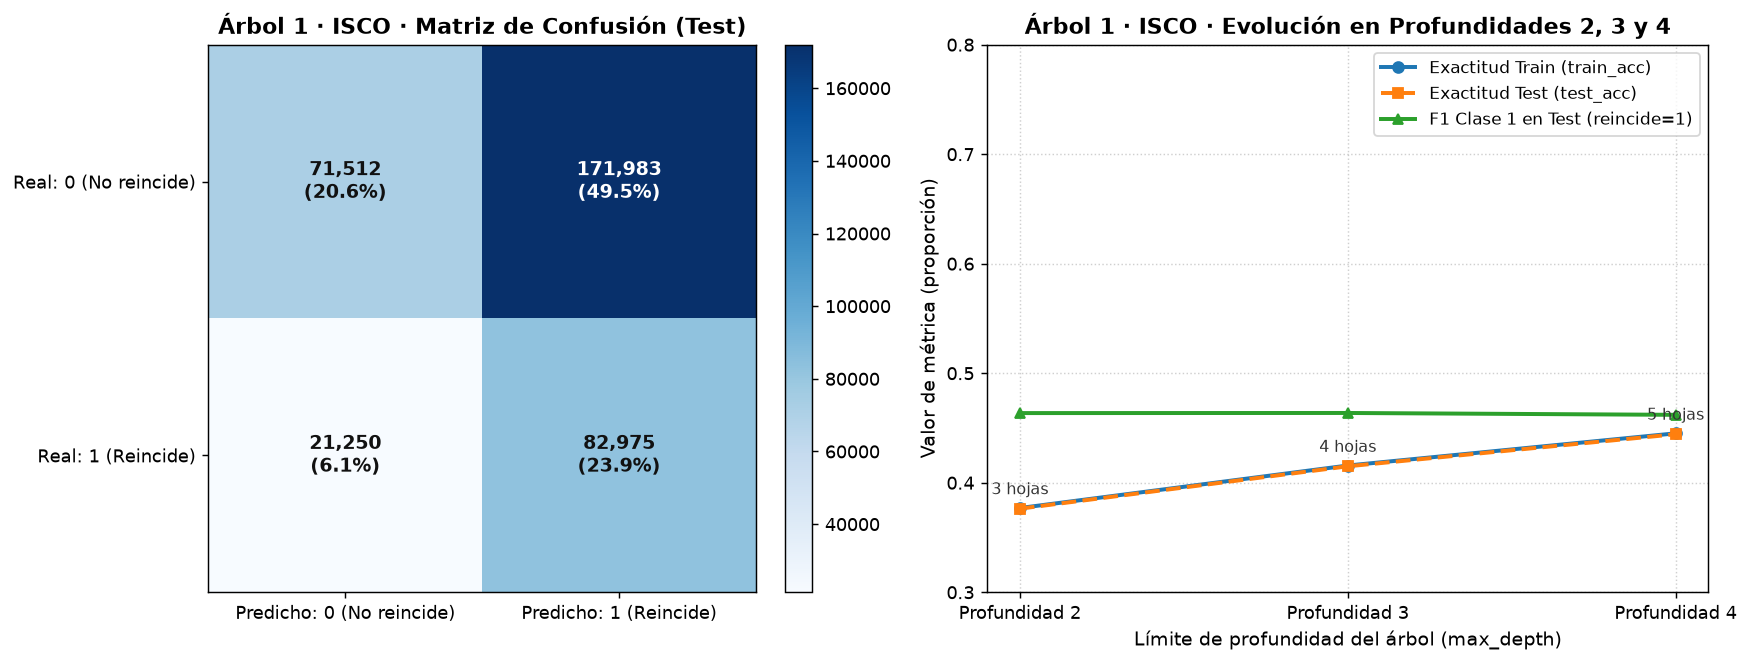

In [6]:
b_isco = tree_bundles[BLOCK_ISCO]

display(Markdown("#### Bitácora de 10 intentos en CV agrupado · Árbol 1 (ISCO)"))
display(b_isco.tuning_result.attempts_log)

display(Markdown("#### Métricas del Árbol 1 final (`max_depth=4`) en Train y Test"))
display(b_isco.metrics_df)

display(Markdown("#### Reporte honesto de brecha frente a la meta `0.85` · Árbol 1 (ISCO)"))
display(b_isco.tuning_result.gap_report)

display(Markdown("#### Tabla de profundidades 2, 3 y 4 · Árbol 1 (ISCO)"))
display(b_isco.depth_df)

display(Markdown("#### Desempeño y Lift por hoja terminal · Árbol 1 (ISCO)"))
display(b_isco.leaf_lift_df)

fig_eval_isco = plot_depth_and_confusion_panel(
    b_isco.depth_df,
    b_isco.confusion_matrices["test"],
    tree_label_es=b_isco.tree_label_es,
    output_path=config.figures_dir / "01_panel_evaluacion_isco.png",
)
plt.show()

**Interpretación del Árbol 1 · ISCO (*¿Qué es el oficio?*)**:
1. **Selección en CV agrupado y efecto del desbalance**:
   - Sin ponderación de clases (Intento 1, `class_weight=None`), como ningún Gran Grupo ISCO a 1 dígito supera el `50%` de tasa de reincidencia (el máximo es el Gran Grupo 5 con `33.84%`), todas las hojas predicen `0` y el modelo colapsa al `DummyClassifier` (`F1 = 0.0000`).
   - Al aplicar `class_weight="balanced"` (Intento 2, seleccionado en CV con `max_depth=4`), el árbol alcanza en **Test**: **`accuracy = 0.4443`**, **`precision_clase_1 = 0.3254`**, **`recall_clase_1 = 0.7961`** y **`f1_clase_1 = 0.4620`**, superando claramente al baseline en detección de clase 1 (`F1 = 0.4620` vs. `0.0000`) y capturando el **`86.8%` del techo F1 del proyecto (`0.5321`)** usando únicamente la macro-categoría ocupacional a 1 dígito.
2. **Evaluación de las variantes a 2 dígitos y Top-50 a 4 dígitos (advertencia de circularidad)**:
   - La variante de **2 dígitos** (Intento 9) obtiene menor `F1` en CV (`0.3407`) porque fragmenta el árbol en pocos subgrupos pequeños a profundidad 4.
   - La variante **Top-50 a 4 dígitos** (Intento 10) sube el `F1` en CV de `0.4620` a **`0.4794`** (`+0.0174` puntos en F1) y la exactitud a `0.5295`. Sin embargo, como se advirtió en la Sección 2, usar 4 dígitos ISCO introduce **alta circularidad parcial** (casi identifica al código de oficio `occupation_code` con el que se calculó `reincide`) y la ganancia en `F1` es marginal (`+1.74` puntos porcentuales), por lo que mantenemos los **10 Grandes Grupos ISCO a 1 dígito** como versión principal y dejamos registrada la comparación por si deseas confirmar otro criterio.
3. **Lectura en prosa de la tabla de profundidades (`2, 3 y 4`)**:
   - Con `max_depth=2` (`3` hojas), la exactitud es `0.3769` en Train y `0.3763` en Test (`gap = 0.0006`).
   - Con `max_depth=3` (`4` hojas), la exactitud sube a `0.4157` en Train y `0.4150` en Test (`gap = 0.0007`).
   - Con `max_depth=4` (`5` hojas), la exactitud mejora a **`0.4451` en Train y `0.4443` en Test** con una brecha casi nula (`gap_train_test = 0.0008`), confirmando ausencia total de sobreajuste (*overfitting*).
   - ¿Por qué un árbol de profundidad 4 sobre 10 dummies mutuamente excluyentes tiene exactamente `5` hojas? Porque cuando una rama cumple `isco_major_k > 0.5` (es decir, el empleo pertenece al grupo `k`), las otras 9 dummies valen `0` de forma determinista en ese nodo hijo derecho, convirtiéndolo inmediatamente en una hoja terminal pura en `X`.

---
### 4.2 · Árbol 2 · Nivel Educativo (*¿Quién ejerce el oficio?*)
*Qué hacemos y por qué*: Evaluamos los 10 intentos en CV agrupado para el bloque de nivel educativo (`nivel_educativo_ord` + bandera `educacion_no_reportada` y sus variantes de codificación), reportamos métricas en Train y Test, brecha honesta frente a `0.85`, tabla de profundidades `2, 3 y 4` y tabla de hojas con su *Lift*.

#### Bitácora de 10 intentos en CV agrupado · Árbol 2 (Nivel educativo)

intento,variante_variables,configuracion,criterion,max_depth,min_samples_leaf,class_weight,ccp_alpha,cv_accuracy,cv_precision_1,cv_recall_1,cv_f1_1,test_accuracy,test_precision_1,test_recall_1,test_f1_1,decision
1,ordinal_plus_flag,Ordinal (0..4) + bandera no reportado · Gini sin pesos (base),gini,4,100,None (sin pesos),0.0000,0.6999,0.0000,0.0000,0.000,NaN,NaN,NaN,NaN,Descartado en CV (colapsa a clase mayoritaria 0; F1=0)
2,ordinal_plus_flag,Ordinal (0..4) + bandera no reportado · Gini + class_weight='balanced',gini,4,100,balanced,0.0000,0.3752,0.3091,0.8762,0.457,0.376,0.3088,0.8738,0.4564,SELECCIONADO en CV (mejor honesto; <0.85 por techo de señal)
3,ordinal_plus_flag,Ordinal (0..4) + bandera no reportado · Entropy + class_weight='balanced',entropy,4,100,balanced,0.0000,0.3752,0.3091,0.8762,0.457,NaN,NaN,NaN,NaN,Descartado en CV (menor F1/equilibrio que el seleccionado)
4,ordinal_plus_flag,"Ordinal (0..4) + bandera no reportado · Gini + balanced + hoja mín 1,000",gini,4,1000,balanced,0.0000,0.3752,0.3091,0.8762,0.457,NaN,NaN,NaN,NaN,Descartado en CV (menor F1/equilibrio que el seleccionado)
5,ordinal_plus_flag,Ordinal (0..4) + bandera no reportado · Gini + peso clase 1 (1:1.9),gini,4,500,"{0:1.0, 1:1.9}",0.0000,0.6999,0.0000,0.0000,0.000,NaN,NaN,NaN,NaN,Descartado en CV (colapsa a clase mayoritaria 0; F1=0)
6,ordinal_plus_flag,Ordinal (0..4) + bandera no reportado · Gini + peso clase 1 (1:2.2),gini,4,500,"{0:1.0, 1:2.2}",0.0000,0.6999,0.0000,0.0000,0.000,NaN,NaN,NaN,NaN,Descartado en CV (colapsa a clase mayoritaria 0; F1=0)
7,reported_ordinal_plus_flag,Ordinal separado (-1 vs 1..4) + bandera no reportado · Gini + balanced,gini,4,500,balanced,0.0000,0.3752,0.3091,0.8762,0.457,NaN,NaN,NaN,NaN,Descartado en CV (menor F1/equilibrio que el seleccionado)
8,ordinal_plus_flag_and_dummies,Ordinal + bandera no reportado + indicadores de ciclo · Gini + balanced,gini,4,500,balanced,0.0000,0.3752,0.3091,0.8762,0.457,NaN,NaN,NaN,NaN,Descartado en CV (menor F1/equilibrio que el seleccionado)
9,ordinal_plus_flag,Ordinal (0..4) + bandera no reportado · Gini + balanced + ccp_alpha=1e-4,gini,4,500,balanced,0.0001,0.3752,0.3091,0.8762,0.457,NaN,NaN,NaN,NaN,Descartado en CV (menor F1/equilibrio que el seleccionado)
10,ordinal_plus_flag,Ordinal (0..4) + bandera no reportado · Profundidad 3 + balanced,gini,3,500,balanced,0.0000,0.3752,0.3091,0.8762,0.457,NaN,NaN,NaN,NaN,Descartado en CV (menor F1/equilibrio que el seleccionado)


#### Métricas del Árbol 2 final (`max_depth=4`) en Train y Test

arbol,particion,profundidad_efectiva,n_hojas,accuracy,precision_clase_1,recall_clase_1,f1_clase_1,tn,fp,fn,tp
Árbol 2 · Nivel educativo,Train (80%),3,5,0.3752,0.3091,0.8762,0.4570,156133,817414,51692,365779
Árbol 2 · Nivel educativo,Test (20%),3,5,0.3760,0.3088,0.8738,0.4564,39679,203816,13152,91073


#### Reporte honesto de brecha frente a la meta `0.85` · Árbol 2 (Nivel educativo)

metrica,meta_objetivo,valor_cv_train,valor_test_final,brecha_vs_085,cumple_085
Exactitud global (Accuracy),0.85,0.3752,0.3760,0.4740,No (límite honesto de señal)
Precisión clase 1 (Precision reincide=1),0.85,0.3091,0.3088,0.5412,No (límite honesto de señal)
Sensibilidad clase 1 (Recall reincide=1),0.85,0.8762,0.8738,0.0000,Sí
F1-Score clase 1 (F1 reincide=1),0.85,0.4570,0.4564,0.3936,No (límite honesto de señal)


#### Tabla de profundidades 2, 3 y 4 · Árbol 2 (Nivel educativo)

max_depth,profundidad_alcanzada,n_leaves,train_acc,test_acc,gap_train_test,train_f1_clase_1,test_precision_clase_1,test_recall_clase_1,test_f1_clase_1
2,2,4,0.3752,0.376,-0.0008,0.457,0.3088,0.8738,0.4564
3,3,5,0.3752,0.376,-0.0008,0.457,0.3088,0.8738,0.4564
4,3,5,0.3752,0.376,-0.0008,0.457,0.3088,0.8738,0.4564


#### Desempeño y Lift por hoja terminal · Árbol 2 (Nivel educativo)

hoja_id,profundidad,predice_reincide,n_train,pct_train,tasa_clase1_train,tasa_base_train,lift_train,n_test,pct_test,tasa_clase1_test,tasa_base_test,lift_test,condiciones_hoja_es
4,3,1,548687,39.44,0.3109,0.3001,1.036,136581,39.28,0.3120,0.2997,1.041,nivel_educativo_ord <= 2.5 (hasta Bachelor (2)) Y nivel_educativo_ord <= 1.5 (hasta Secondary school (1)) Y nivel_educativo_ord > 0.5 (desde Secondary school (1) o superior)
3,3,1,160664,11.55,0.3080,0.3001,1.026,40270,11.58,0.3054,0.2997,1.019,nivel_educativo_ord <= 2.5 (hasta Bachelor (2)) Y nivel_educativo_ord <= 1.5 (hasta Secondary school (1)) Y nivel_educativo_ord <= 0.5 (hasta No reportado (0))
5,2,1,473842,34.06,0.3075,0.3001,1.025,118038,33.95,0.3064,0.2997,1.022,nivel_educativo_ord <= 2.5 (hasta Bachelor (2)) Y nivel_educativo_ord > 1.5 (desde Bachelor (2) o superior)
7,2,0,201851,14.51,0.2493,0.3001,0.831,51275,14.75,0.2499,0.2997,0.834,nivel_educativo_ord > 2.5 (desde Master (3) o superior) Y nivel_educativo_ord <= 3.5 (hasta Master (3))
8,2,0,5974,0.43,0.2283,0.3001,0.761,1556,0.45,0.2166,0.2997,0.723,nivel_educativo_ord > 2.5 (desde Master (3) o superior) Y nivel_educativo_ord > 3.5 (desde PhD (4) o superior)


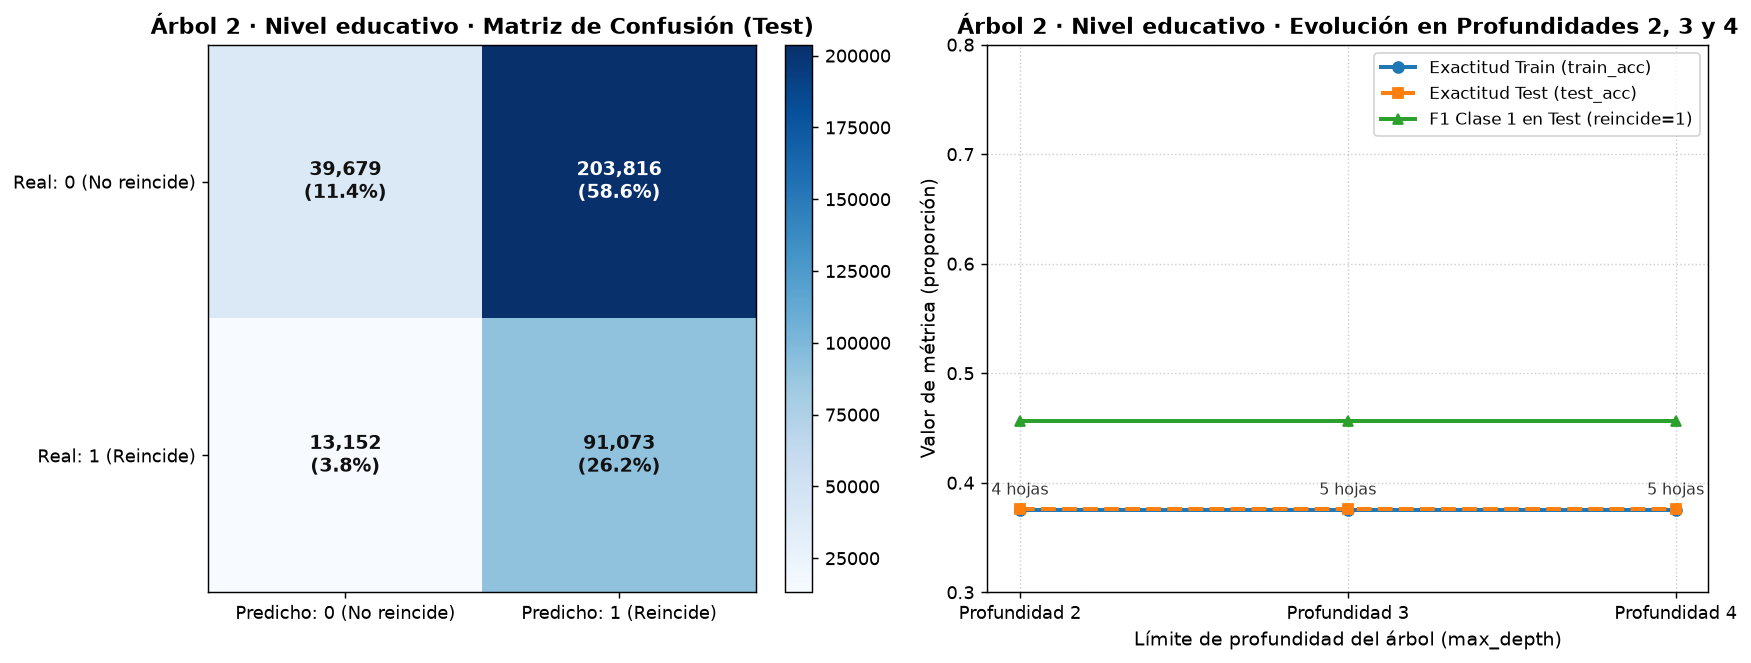

In [7]:
b_edu = tree_bundles[BLOCK_EDUCATION]

display(Markdown("#### Bitácora de 10 intentos en CV agrupado · Árbol 2 (Nivel educativo)"))
display(b_edu.tuning_result.attempts_log)

display(Markdown("#### Métricas del Árbol 2 final (`max_depth=4`) en Train y Test"))
display(b_edu.metrics_df)

display(Markdown("#### Reporte honesto de brecha frente a la meta `0.85` · Árbol 2 (Nivel educativo)"))
display(b_edu.tuning_result.gap_report)

display(Markdown("#### Tabla de profundidades 2, 3 y 4 · Árbol 2 (Nivel educativo)"))
display(b_edu.depth_df)

display(Markdown("#### Desempeño y Lift por hoja terminal · Árbol 2 (Nivel educativo)"))
display(b_edu.leaf_lift_df)

fig_eval_edu = plot_depth_and_confusion_panel(
    b_edu.depth_df,
    b_edu.confusion_matrices["test"],
    tree_label_es=b_edu.tree_label_es,
    output_path=config.figures_dir / "02_panel_evaluacion_educacion.png",
)
plt.show()

**Interpretación del Árbol 2 · Nivel Educativo (*¿Quién ejerce el oficio?*)**:
1. **Hallazgo empírico sobre el poder separador de la educación**:
   - En todo el dataset existen exactamente **5 categorías educativas**, cuyas tasas de reincidencia en Train son: `Secondary school = 31.09%` (`Lift = 1.036`), `No reportado = 30.80%` (`Lift = 1.026`), `Bachelor = 30.75%` (`Lift = 1.025`), `Master = 24.93%` (`Lift = 0.831`) y `PhD = 22.83%` (`Lift = 0.761`).
   - Como el espacio de entrada tiene únicamente 5 puntos posibles, **cualquier árbol con `max_depth >= 3` ya agota por completo las 5 categorías en 5 hojas** (por eso la profundidad efectiva alcanzada al pedir `max_depth=4` es `3` con `5` hojas).
   - En **Test**, el árbol seleccionado (Intento 2, `class_weight="balanced"`) alcanza **`recall_clase_1 = 0.8738`** (superando `0.85` en sensibilidad porque clasifica como `1` a los tres grupos con tasa superior al promedio: `Secondary school`, `No reportado` y `Bachelor`, que suman el `84.81%` de los registros), pero obtiene **`accuracy = 0.3760`**, **`precision_clase_1 = 0.3088`** y **`f1_clase_1 = 0.4564`**.
2. **Lectura en prosa de la tabla de profundidades (`2, 3 y 4`)**:
   - En `max_depth=2` (`4` hojas), `max_depth=3` (`5` hojas) y `max_depth=4` (`5` hojas), la exactitud permanece en **`0.3752` en Train y `0.3760` en Test** (`gap_train_test = -0.0008`) y el `F1` en Test es **`0.4564`**.
   - ¿Por qué no cambian las métricas de predicción entre profundidad 2, 3 y 4? Porque el único corte que cambia la decisión entre predecir `reincide = 1` (tasa `> 30.01%`) y `reincide = 0` (tasa `< 30.01%`) ocurre ya en la **raíz (Nivel 1)**: `nivel_educativo_ord <= 2.5` (`No reportado`, `Secondary school` y `Bachelor`, todos con `Lift > 1.02`) frente a `nivel_educativo_ord > 2.5` (`Master` y `PhD`, ambos con `Lift < 0.84`). Los cortes de nivel 2 y 3 separan entre sí a `No reportado`, `Secondary school` y `Bachelor` (y a `Master` de `PhD`), refinando las tasas y el *Lift* de cada hoja sin cambiar el signo de la clase predicha.

---
### 4.3 · Árbol 3 · Competencias (*¿Qué exige el oficio?*)
*Qué hacemos y por qué*: Evaluamos los 10 intentos en CV agrupado para el bloque de competencias ESCO (`n_skills_essential`, `n_skills_competence`, `n_skills_knowledge` en unidades reales sin escalar, más variantes con bandera `tiene_knowledge` y proporciones teórico-prácticas), mostramos métricas en Train y Test, brecha frente a `0.85`, tabla de profundidades `2, 3 y 4` y tabla de las `15` hojas terminales ordenadas por *Lift*.

#### Bitácora de 10 intentos en CV agrupado · Árbol 3 (Competencias)

intento,variante_variables,configuracion,criterion,max_depth,min_samples_leaf,class_weight,ccp_alpha,cv_accuracy,cv_precision_1,cv_recall_1,cv_f1_1,test_accuracy,test_precision_1,test_recall_1,test_f1_1,decision
1,counts_only,"3 conteos ESCO (essential, competence, knowledge) · Gini sin pesos (base)",gini,4,100,None (sin pesos),0.0000,0.7061,0.5488,0.1171,0.1930,NaN,NaN,NaN,NaN,Descartado en CV (menor F1/equilibrio que el seleccionado)
2,counts_only,3 conteos ESCO · Gini + class_weight='balanced',gini,4,100,balanced,0.0000,0.5783,0.3727,0.5930,0.4577,0.5777,0.3715,0.5909,0.4562,SELECCIONADO en CV (mejor honesto; <0.85 por techo de señal)
3,counts_only,3 conteos ESCO · Entropy + class_weight='balanced',entropy,4,100,balanced,0.0000,0.5783,0.3727,0.5930,0.4577,NaN,NaN,NaN,NaN,Descartado en CV (menor F1/equilibrio que el seleccionado)
4,counts_only,"3 conteos ESCO · Gini + balanced + hoja mín 1,000",gini,4,1000,balanced,0.0000,0.5781,0.3726,0.5931,0.4577,NaN,NaN,NaN,NaN,Descartado en CV (menor F1/equilibrio que el seleccionado)
5,counts_only,3 conteos ESCO · Gini + peso clase 1 (1:1.9),gini,4,500,"{0:1.0, 1:1.9}",0.0000,0.6263,0.4045,0.4127,0.3755,NaN,NaN,NaN,NaN,Descartado en CV (menor F1/equilibrio que el seleccionado)
6,counts_only,3 conteos ESCO · Gini + peso clase 1 (1:2.2),gini,4,500,"{0:1.0, 1:2.2}",0.0000,0.5782,0.3726,0.5927,0.4576,NaN,NaN,NaN,NaN,Descartado en CV (menor F1/equilibrio que el seleccionado)
7,counts_plus_flag,3 conteos ESCO + bandera tiene_knowledge · Gini + balanced,gini,4,500,balanced,0.0000,0.5781,0.3726,0.5931,0.4577,NaN,NaN,NaN,NaN,Descartado en CV (menor F1/equilibrio que el seleccionado)
8,counts_plus_ratios,3 conteos ESCO + proporción teórica y diferencia práctica-teórica · Gini + balanced,gini,4,500,balanced,0.0000,0.6152,0.3947,0.5291,0.4521,NaN,NaN,NaN,NaN,Descartado en CV (menor F1/equilibrio que el seleccionado)
9,counts_plus_ratios,"3 conteos ESCO + proporciones · Entropy + balanced + hoja mín 1,000",entropy,4,1000,balanced,0.0000,0.6169,0.3955,0.5236,0.4506,NaN,NaN,NaN,NaN,Descartado en CV (menor F1/equilibrio que el seleccionado)
10,counts_only,3 conteos ESCO · Gini + balanced + poda ccp_alpha=1e-4,gini,4,500,balanced,0.0001,0.5772,0.3721,0.5946,0.4577,NaN,NaN,NaN,NaN,Descartado en CV (menor F1/equilibrio que el seleccionado)


#### Métricas del Árbol 3 final (`max_depth=4`) en Train y Test

arbol,particion,profundidad_efectiva,n_hojas,accuracy,precision_clase_1,recall_clase_1,f1_clase_1,tn,fp,fn,tp
Árbol 3 · Competencias,Train (80%),4,15,0.5783,0.3727,0.5930,0.4577,556850,416697,169899,247572
Árbol 3 · Competencias,Test (20%),4,15,0.5777,0.3715,0.5909,0.4562,139313,104182,42643,61582


#### Reporte honesto de brecha frente a la meta `0.85` · Árbol 3 (Competencias)

metrica,meta_objetivo,valor_cv_train,valor_test_final,brecha_vs_085,cumple_085
Exactitud global (Accuracy),0.85,0.5783,0.5777,0.2723,No (límite honesto de señal)
Precisión clase 1 (Precision reincide=1),0.85,0.3727,0.3715,0.4785,No (límite honesto de señal)
Sensibilidad clase 1 (Recall reincide=1),0.85,0.5930,0.5909,0.2591,No (límite honesto de señal)
F1-Score clase 1 (F1 reincide=1),0.85,0.4577,0.4562,0.3938,No (límite honesto de señal)


#### Tabla de profundidades 2, 3 y 4 · Árbol 3 (Competencias)

max_depth,profundidad_alcanzada,n_leaves,train_acc,test_acc,gap_train_test,train_f1_clase_1,test_precision_clase_1,test_recall_clase_1,test_f1_clase_1
2,2,4,0.5671,0.5672,-0.0002,0.4441,0.3609,0.5759,0.4438
3,3,8,0.5470,0.5473,-0.0002,0.4623,0.3589,0.6488,0.4621
4,4,15,0.5783,0.5777,0.0005,0.4577,0.3715,0.5909,0.4562


#### Desempeño y Lift por hoja terminal · Árbol 3 (Competencias)

hoja_id,profundidad,predice_reincide,n_train,pct_train,tasa_clase1_train,tasa_base_train,lift_train,n_test,pct_test,tasa_clase1_test,tasa_base_test,lift_test,condiciones_hoja_es
28,4,1,12616,0.91,0.6368,0.3001,2.122,3053,0.88,0.6315,0.2997,2.107,n_skills_competence > 18.5 (19 o más) Y n_skills_essential > 20.5 (21 o más) Y n_skills_knowledge > 25.5 (26 o más) Y n_skills_competence > 38.00
21,3,1,76910,5.53,0.5338,0.3001,1.779,19213,5.53,0.5294,0.2997,1.766,n_skills_competence > 18.5 (19 o más) Y n_skills_essential <= 20.5 (20 o menos) Y n_skills_knowledge > 0.5 (1 o más)
7,4,1,85327,6.13,0.3494,0.3001,1.164,21317,6.13,0.3498,0.2997,1.167,n_skills_competence <= 18.5 (18 o menos) Y n_skills_essential <= 10.5 (10 o menos) Y n_skills_essential > 9.5 (10 o más) Y n_skills_knowledge <= 3.5 (3 o menos)
24,4,1,455363,32.74,0.3448,0.3001,1.149,113501,32.64,0.3435,0.2997,1.146,n_skills_competence > 18.5 (19 o más) Y n_skills_essential > 20.5 (21 o más) Y n_skills_knowledge <= 25.5 (25 o menos) Y n_skills_knowledge <= 7.5 (7 o menos)
20,4,1,34053,2.45,0.3426,0.3001,1.142,8680,2.50,0.3501,0.2997,1.168,n_skills_competence > 18.5 (19 o más) Y n_skills_essential <= 20.5 (20 o menos) Y n_skills_knowledge <= 0.5 (0 o menos) Y n_skills_essential > 19.5 (20 o más)
14,4,0,220248,15.83,0.2696,0.3001,0.898,55251,15.89,0.2701,0.2997,0.901,n_skills_competence <= 18.5 (18 o menos) Y n_skills_essential > 10.5 (11 o más) Y n_skills_essential > 16.5 (17 o más) Y n_skills_knowledge <= 6.5 (6 o menos)
25,4,0,84198,6.05,0.2635,0.3001,0.878,21182,6.09,0.2706,0.2997,0.903,n_skills_competence > 18.5 (19 o más) Y n_skills_essential > 20.5 (21 o más) Y n_skills_knowledge <= 25.5 (25 o menos) Y n_skills_knowledge > 7.5 (8 o más)
11,4,0,49336,3.55,0.2515,0.3001,0.838,12159,3.50,0.2487,0.2997,0.830,n_skills_competence <= 18.5 (18 o menos) Y n_skills_essential > 10.5 (11 o más) Y n_skills_essential <= 16.5 (16 o menos) Y n_skills_knowledge <= 0.5 (0 o menos)
5,4,0,31823,2.29,0.2501,0.3001,0.833,8093,2.33,0.2528,0.2997,0.843,n_skills_competence <= 18.5 (18 o menos) Y n_skills_essential <= 10.5 (10 o menos) Y n_skills_essential <= 9.5 (9 o menos) Y n_skills_knowledge > 1.5 (2 o más)
19,4,0,2449,0.18,0.2474,0.3001,0.824,601,0.17,0.2712,0.2997,0.905,n_skills_competence > 18.5 (19 o más) Y n_skills_essential <= 20.5 (20 o menos) Y n_skills_knowledge <= 0.5 (0 o menos) Y n_skills_essential <= 19.5 (19 o menos)


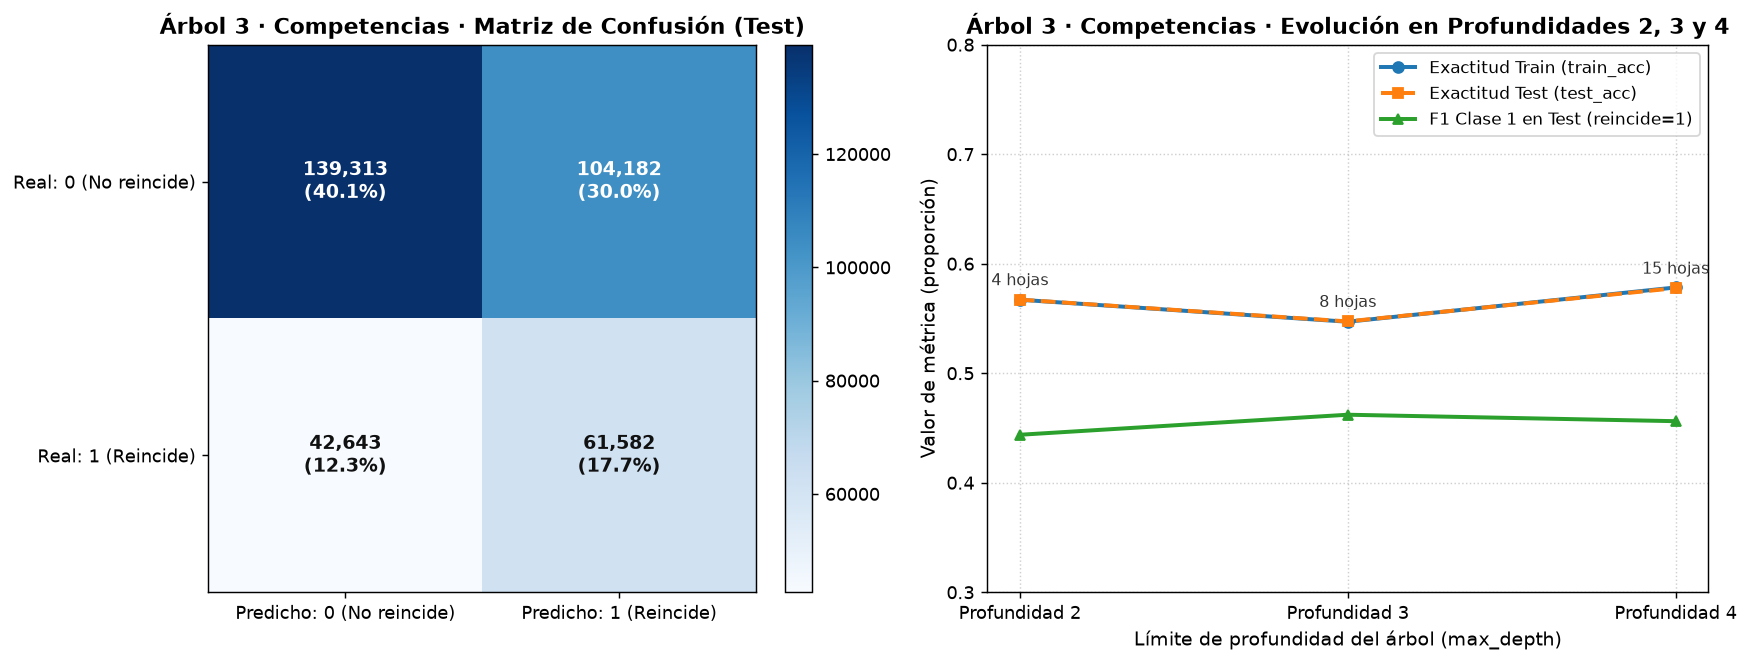

In [8]:
b_skills = tree_bundles[BLOCK_SKILLS]

display(Markdown("#### Bitácora de 10 intentos en CV agrupado · Árbol 3 (Competencias)"))
display(b_skills.tuning_result.attempts_log)

display(Markdown("#### Métricas del Árbol 3 final (`max_depth=4`) en Train y Test"))
display(b_skills.metrics_df)

display(Markdown("#### Reporte honesto de brecha frente a la meta `0.85` · Árbol 3 (Competencias)"))
display(b_skills.tuning_result.gap_report)

display(Markdown("#### Tabla de profundidades 2, 3 y 4 · Árbol 3 (Competencias)"))
display(b_skills.depth_df)

display(Markdown("#### Desempeño y Lift por hoja terminal · Árbol 3 (Competencias)"))
display(b_skills.leaf_lift_df)

fig_eval_skills = plot_depth_and_confusion_panel(
    b_skills.depth_df,
    b_skills.confusion_matrices["test"],
    tree_label_es=b_skills.tree_label_es,
    output_path=config.figures_dir / "03_panel_evaluacion_skills.png",
)
plt.show()

**Interpretación del Árbol 3 · Competencias (*¿Qué exige el oficio?*)**:
1. **El ángulo con mejor equilibrio discriminante y hojas de alto *Lift***:
   - En la bitácora de CV agrupado, el Intento 1 sin pesos (`class_weight=None`) alcanza `accuracy = 0.7061` y `precision_1 = 0.5488`, pero con un `recall_1` de apenas `0.1171` (`F1 = 0.1930`), ya que solo predice `1` en los nichos extremos donde la tasa de reincidencia supera el `50%`.
   - Con `class_weight="balanced"` sobre los 3 conteos puros en unidades reales (Intento 2, seleccionado en CV con `max_depth=4` y `15` hojas), el árbol logra en **Test**: **`accuracy = 0.5777`**, **`precision_clase_1 = 0.3715`**, **`recall_clase_1 = 0.5909`** y **`f1_clase_1 = 0.4562`**, con la mayor precisión y exactitud de los tres árboles balanceados y hojas que alcanzan hasta **`Lift = 2.11x` en Test (`63.15%` de reincidencia en la Hoja 28)** y **`Lift = 1.77x` (`52.94%` de reincidencia en la Hoja 21)**.
2. **Lectura en prosa de la tabla de profundidades (`2, 3 y 4`)**:
   - En `max_depth=2` (`4` hojas), `train_acc = 0.5671` y `test_acc = 0.5672` (`gap = -0.0002`, `test_f1 = 0.4438`).
   - En `max_depth=3` (`8` hojas), el árbol amplía la cobertura de hojas positivas (`recall = 0.6488`, `test_f1 = 0.4621`, `train_acc = 0.5470`, `test_acc = 0.5473`, `gap = -0.0002`).
   - En `max_depth=4` (`15` hojas), el árbol depura las ramas mixtas y sube la exactitud al máximo del bloque (**`train_acc = 0.5783`, `test_acc = 0.5777`, `gap_train_test = 0.0005`**) y la precisión de clase 1 a **`0.3715`**, manteniendo un sobreajuste prácticamente nulo (`0.05` puntos porcentuales entre Train y Test).
3. **Explicación honesta de por qué ningún árbol alcanza `0.85` simultáneo en Test**:
   - Como exige la regla de honestidad científica del curso, **detenemos el ajuste tras los 10 intentos reglamentarios y reportamos que ningún árbol alcanza `0.85` simultáneo en las 4 métricas**.
   - Las tres razones técnicas verificadas son:
     1. **Techo intrínseco de la señal en los datos**: En `6.0_modelado_fase4_jobpath.ipynb`, incluso combinando todas las variables del proyecto (duración del empleo, año de inicio, orden del trabajo en la carrera, vigencia, educación, competencias y las 2,967 dummies de `occupation_code`), el mejor modelo (`Logística Regularizada` con 2,981 columnas) alcanzó **`F1 = 0.5321`** y `HistGradientBoosting` alcanzó **`F1 = 0.5151`**. Nuestros tres árboles simples de profundidad 4 alcanzan `F1` de **`0.4620`**, **`0.4564`** y **`0.4562`** (entre el **`85.7%` y el `86.8%` del techo multivariado total del proyecto**).
     2. **Naturaleza del fenómeno `reincide`**: Repetir un oficio depende fuertemente de la longitud de la trayectoria de la persona y de la duración de sus contratos (variables excluidas de estos tres bloques porque responden a la historia del individuo y no al perfil estático del oficio).
     3. **Restricción pedagógica `max_depth=4` y desbalance `70/30`**: Con una tasa base de `30.01%`, un clasificador con `<= 16` hojas sobre un único bloque de variables no puede tener simultáneamente precisión $\ge 0.85$ y recall $\ge 0.85$ cuando ninguna categoría masiva del dataset supera el `64%` de positividad.

---
## 5 · Visualización de los Árboles (`plot_tree` con `max_depth=4`) y Reglas en Texto (`export_text`)

*Qué hacemos y por qué*: Graficamos los tres árboles finales con `max_depth=4` ajustando el tamaño de figura y fuente para que cada nodo sea completamente legible, y exportamos su estructura exacta mediante `export_text`.

> **Regla fundamental de lectura de umbrales sobre conteos enteros**:
> `scikit-learn` coloca los puntos de corte a mitad de camino entre dos enteros consecutivos (`.5`). Por tanto, en variables de conteo entero como `n_skills_competence`, `n_skills_essential` o `n_skills_knowledge`:
> - **`<= 18.5`** significa **`18 o menos`** (rama izquierda).
> - **`> 18.5`** significa **`19 o más`** (rama derecha).

### 5.1 · Árbol 1 · ISCO (¿Qué es el oficio?)

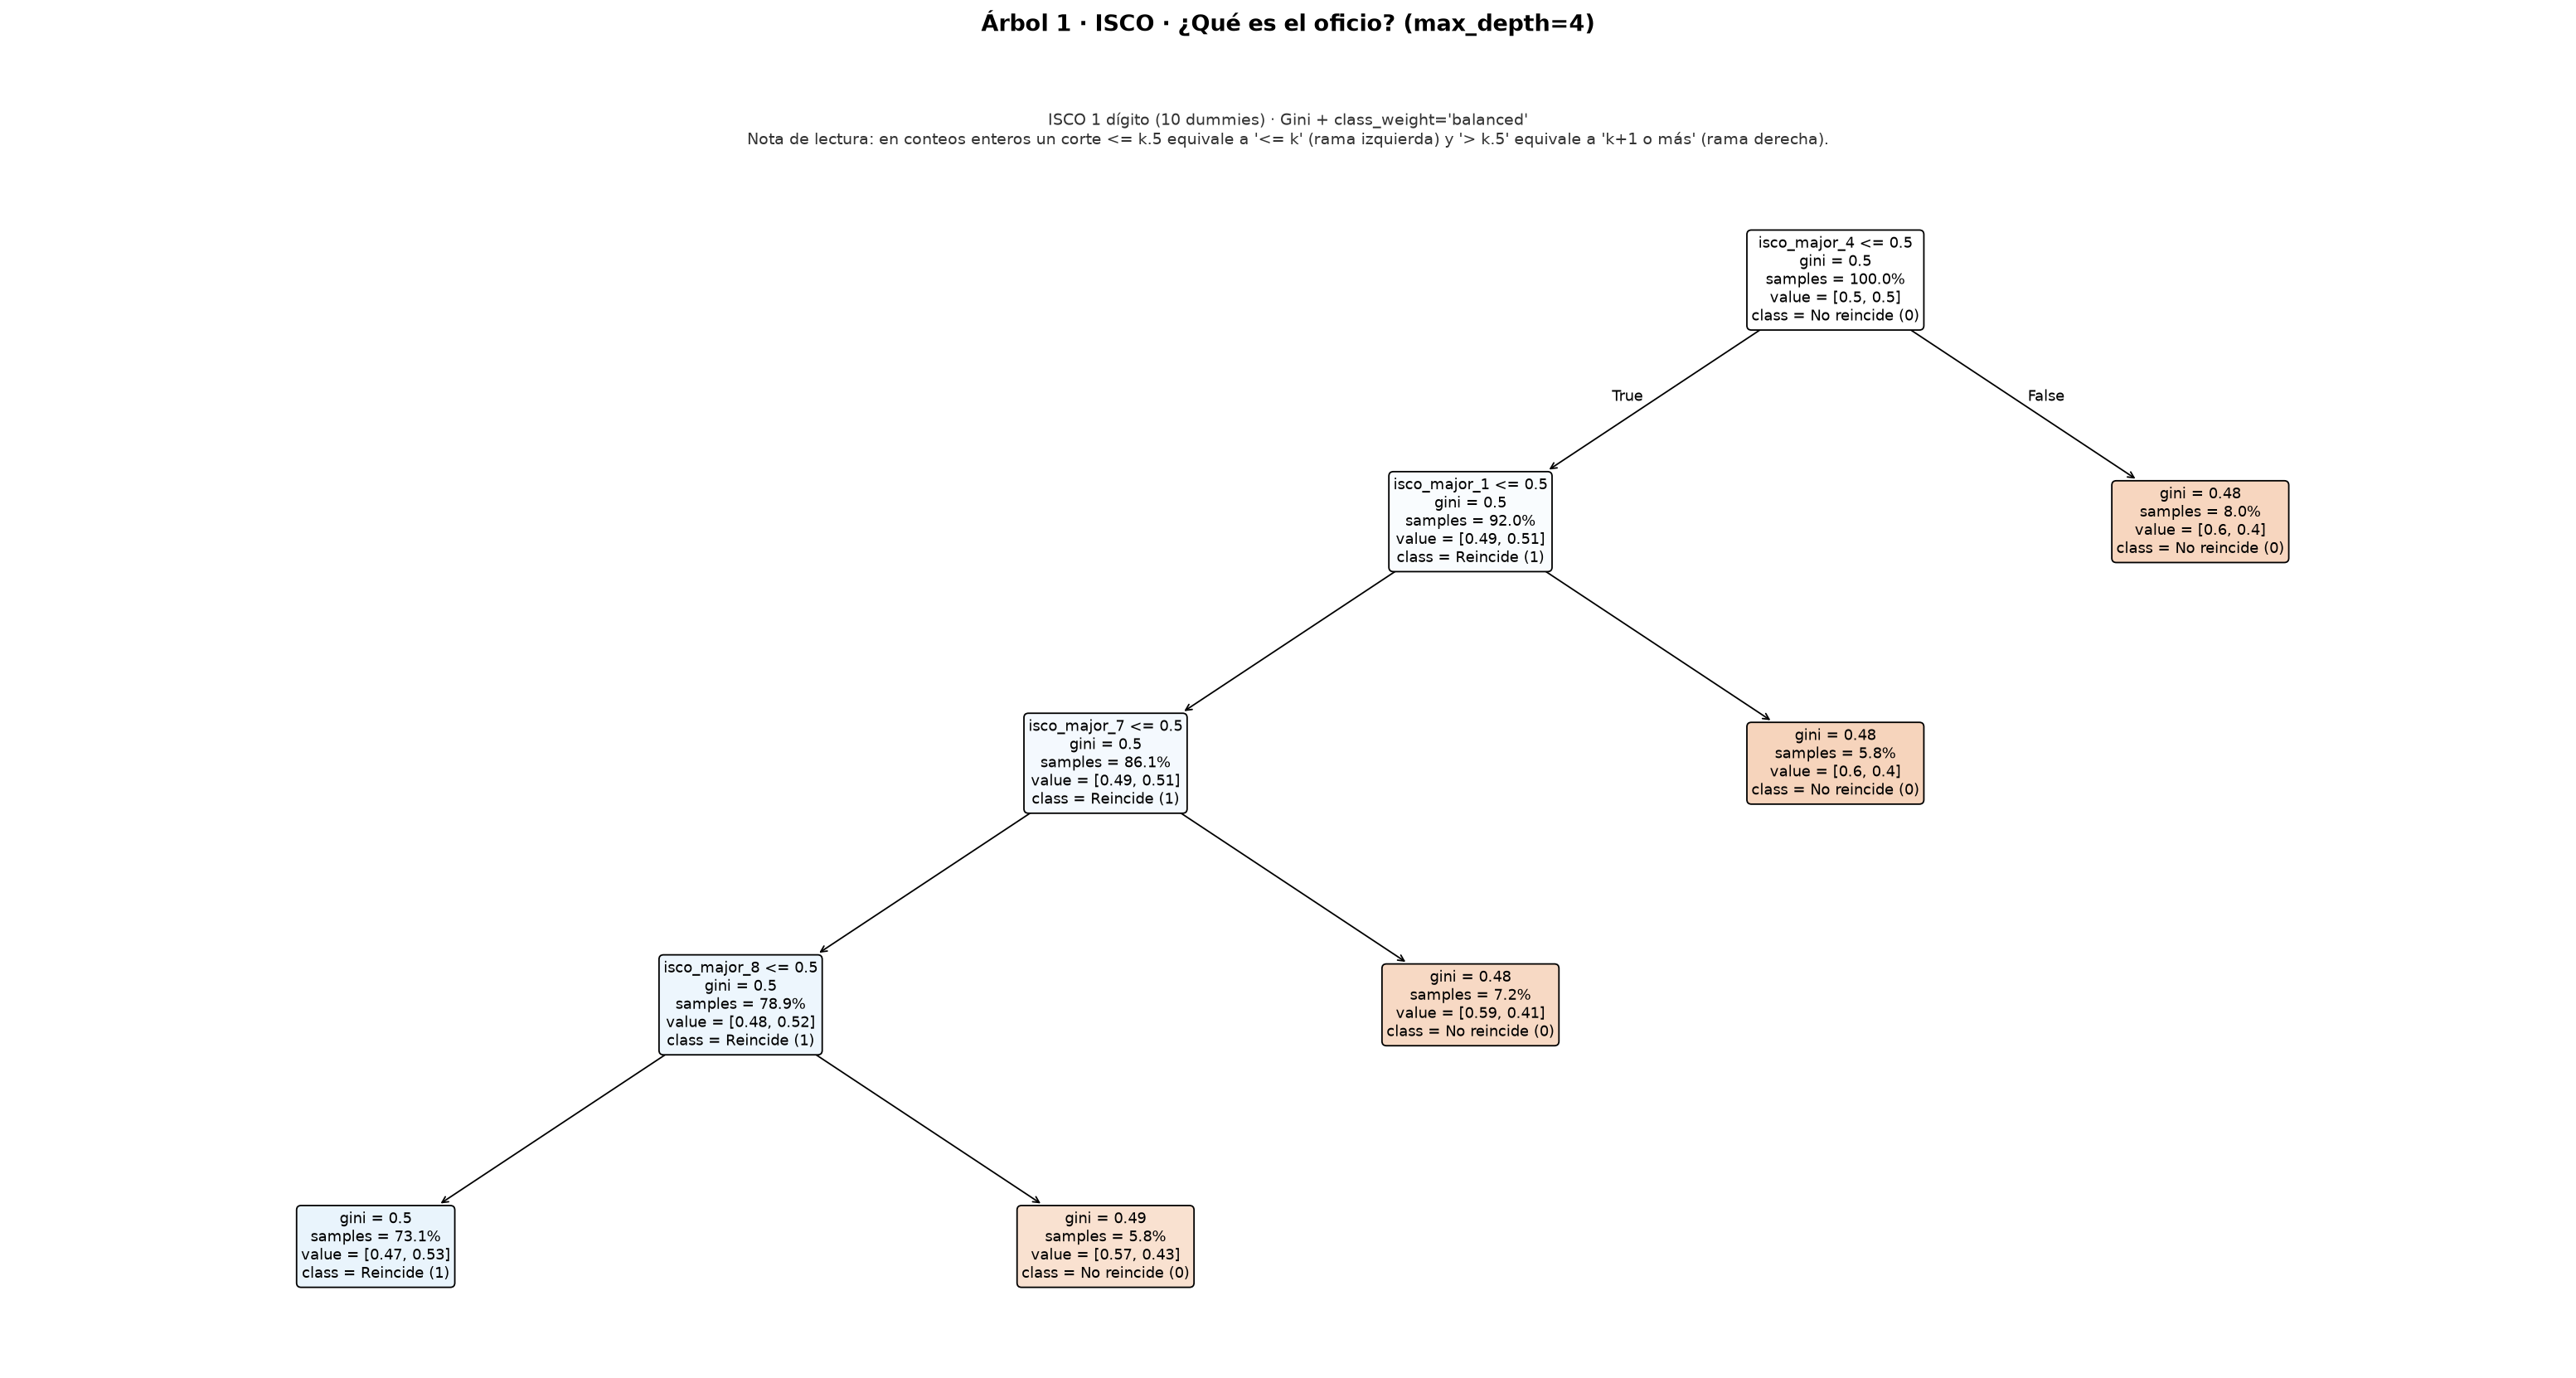

#### Estructura en texto (`export_text`) · Árbol 1 · ISCO

|--- isco_major_4 <= 0.50
|   |--- isco_major_1 <= 0.50
|   |   |--- isco_major_7 <= 0.50
|   |   |   |--- isco_major_8 <= 0.50
|   |   |   |   |--- weights: [489976.19, 552159.22] class: 1
|   |   |   |--- isco_major_8 >  0.50
|   |   |   |   |--- weights: [43415.96, 33141.85] class: 0
|   |   |--- isco_major_7 >  0.50
|   |   |   |--- weights: [55137.95, 38636.33] class: 0
|   |--- isco_major_1 >  0.50
|   |   |--- weights: [45097.67, 29778.18] class: 0
|--- isco_major_4 >  0.50
|   |--- weights: [61881.24, 41793.42] class: 0



### 5.2 · Árbol 2 · Nivel educativo (¿Quién ejerce el oficio?)

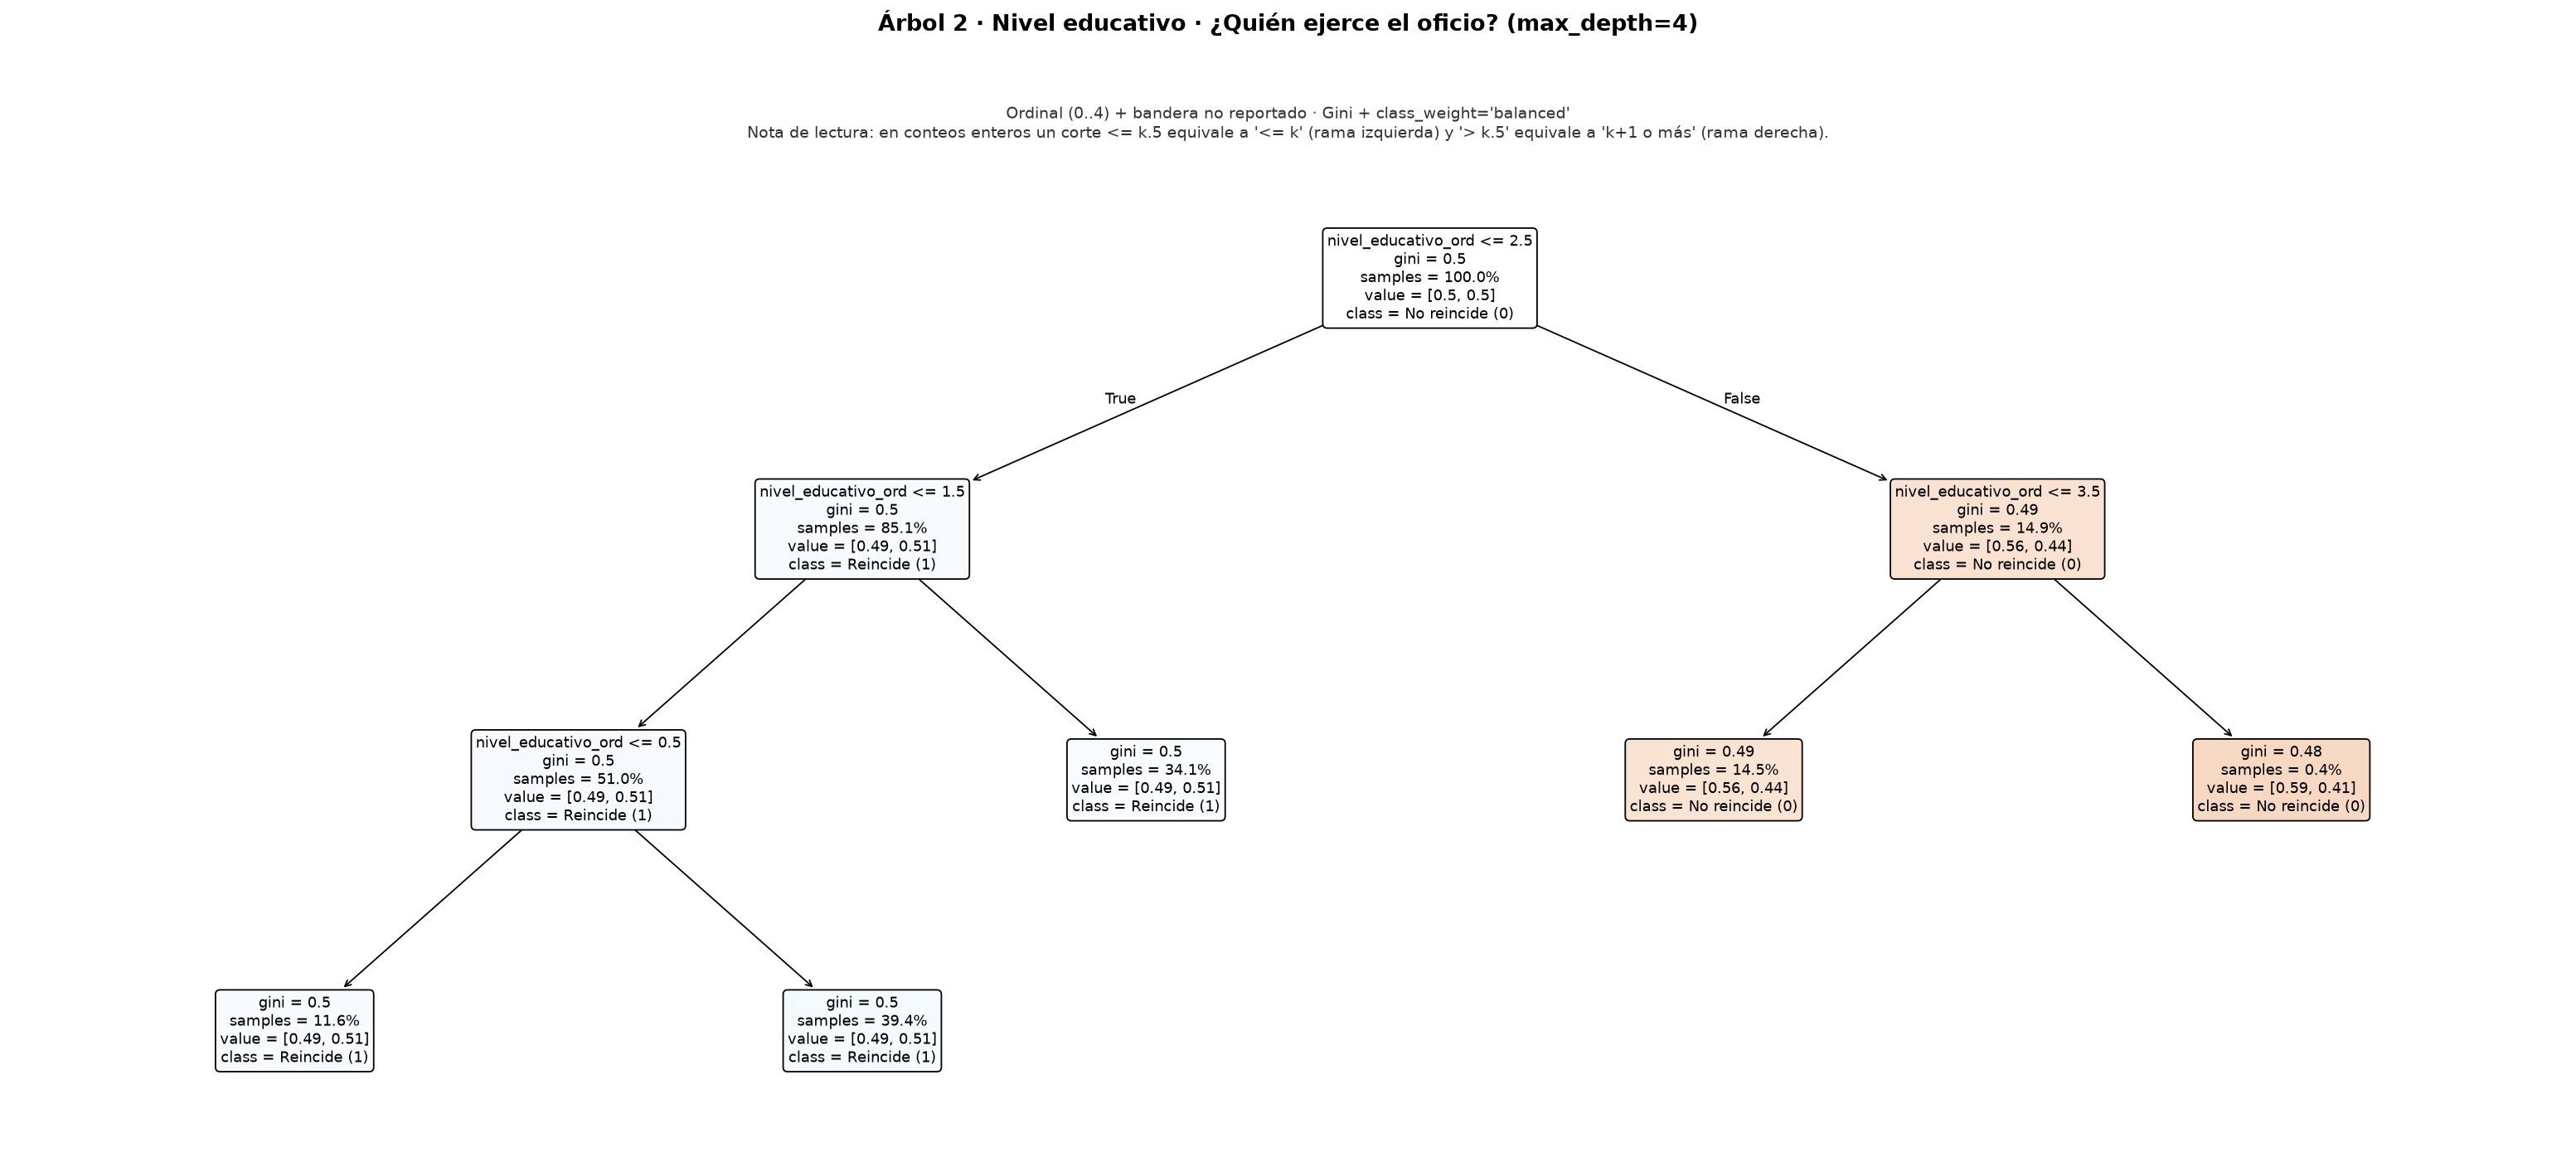

#### Estructura en texto (`export_text`) · Árbol 2 · Nivel educativo

|--- nivel_educativo_ord <= 2.50
|   |--- nivel_educativo_ord <= 1.50
|   |   |--- nivel_educativo_ord <= 0.50
|   |   |   |--- weights: [79423.51, 82450.61] class: 1
|   |   |--- nivel_educativo_ord >  0.50
|   |   |   |--- weights: [270111.65, 284212.22] class: 1
|   |--- nivel_educativo_ord >  1.50
|   |   |--- weights: [234431.30, 242727.01] class: 1
|--- nivel_educativo_ord >  2.50
|   |--- nivel_educativo_ord <= 3.50
|   |   |--- weights: [108249.12, 83846.73] class: 0
|   |--- nivel_educativo_ord >  3.50
|   |   |--- weights: [3293.42, 2272.43] class: 0



### 5.3 · Árbol 3 · Competencias (¿Qué exige el oficio?)

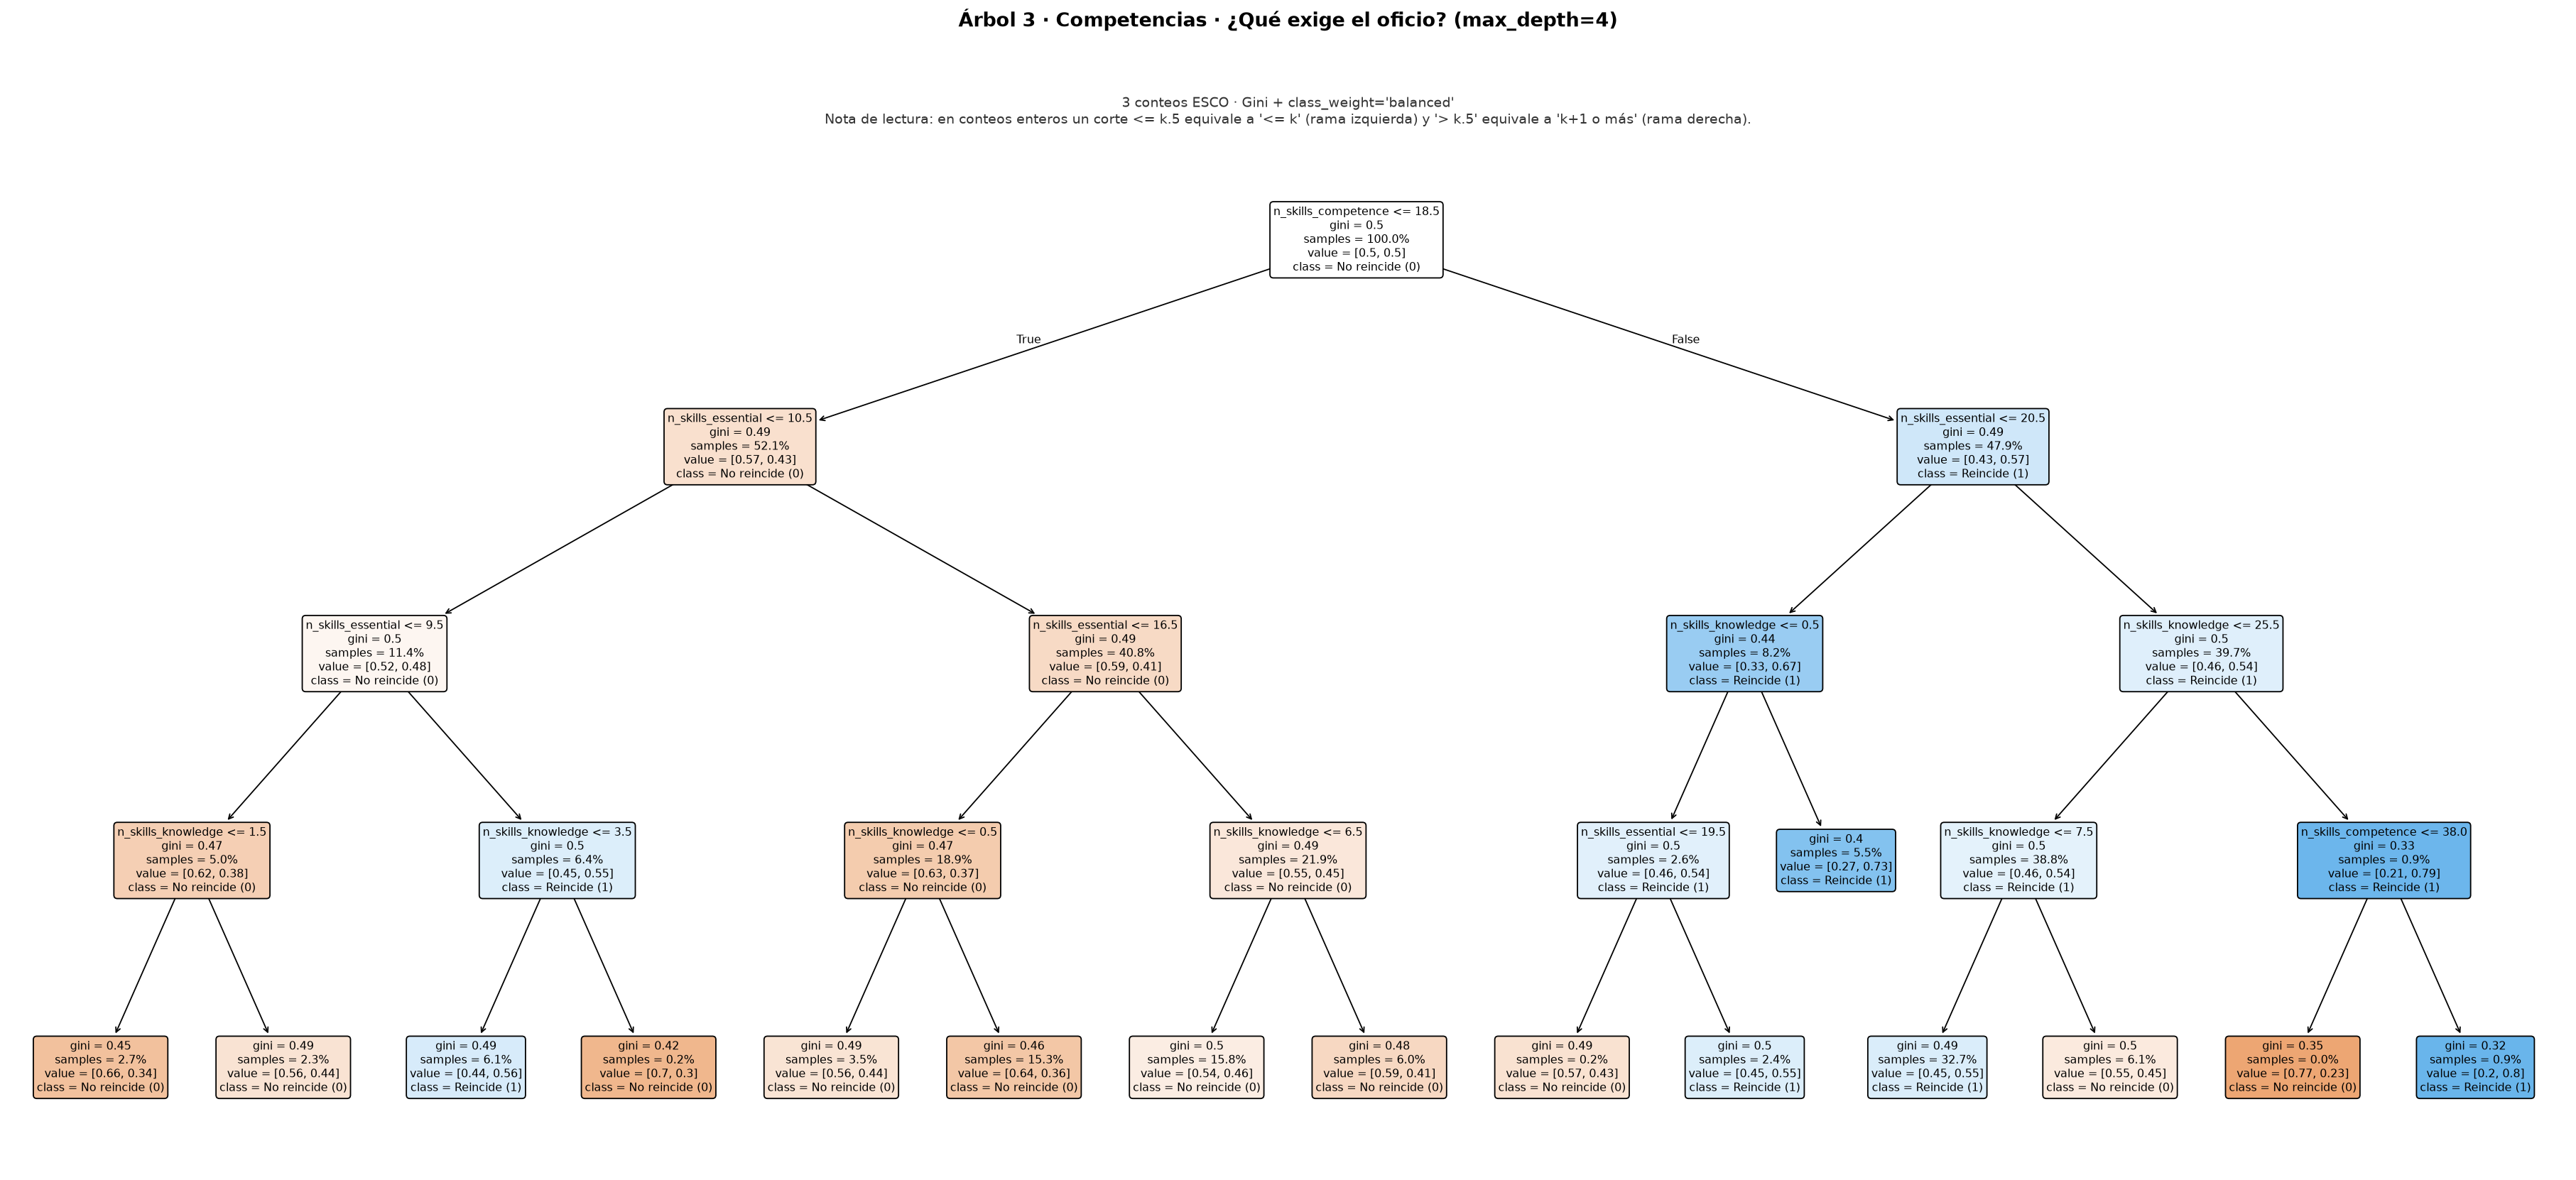

#### Estructura en texto (`export_text`) · Árbol 3 · Competencias

|--- n_skills_competence <= 18.50
|   |--- n_skills_essential <= 10.50
|   |   |--- n_skills_essential <= 9.50
|   |   |   |--- n_skills_knowledge <= 1.50
|   |   |   |   |--- weights: [22300.22, 11245.54] class: 0
|   |   |   |--- n_skills_knowledge >  1.50
|   |   |   |   |--- weights: [17048.61, 13259.74] class: 0
|   |   |--- n_skills_essential >  9.50
|   |   |   |--- n_skills_knowledge <= 3.50
|   |   |   |   |--- weights: [39657.46, 49673.62] class: 1
|   |   |   |--- n_skills_knowledge >  3.50
|   |   |   |   |--- weights: [1908.18, 811.34] class: 0
|   |--- n_skills_essential >  10.50
|   |   |--- n_skills_essential <= 16.50
|   |   |   |--- n_skills_knowledge <= 0.50
|   |   |   |   |--- weights: [26383.06, 20668.46] class: 0
|   |   |   |--- n_skills_knowledge >  0.50
|   |   |   |   |--- weights: [123188.81, 68039.67] class: 0
|   |   |--- n_skills_essential >  16.50
|   |   |   |--- n_skills_knowledge <= 6.50
|   |   |   |   |--- weights: [114922.40, 98934.07] class: 0
|  

In [9]:
for block_id, fig_filename in (
    (BLOCK_ISCO, "04_arbol_1_isco_depth4.png"),
    (BLOCK_EDUCATION, "05_arbol_2_educacion_depth4.png"),
    (BLOCK_SKILLS, "06_arbol_3_skills_depth4.png"),
):
    bundle = tree_bundles[block_id]
    display(Markdown(f"### 5.{list(tree_bundles.keys()).index(block_id) + 1} · {bundle.tree_label_es} ({bundle.sub_question_es})"))
    fig_tree = plot_decision_tree_legible(
        bundle.tuning_result.fitted_tree,
        feature_names=list(bundle.tuning_result.X_train.columns),
        title_es=f"{bundle.tree_label_es} · {bundle.sub_question_es} (max_depth=4)",
        subtitle_es=bundle.tuning_result.selected_spec.description_es,
        output_path=config.figures_dir / fig_filename,
    )
    plt.show()
    display(Markdown(f"#### Estructura en texto (`export_text`) · {bundle.tree_label_es}"))
    print(bundle.export_text_str)

---
## 6 · Las Primeras Preguntas de cada Árbol Calculadas con `decision_path`

*Qué hacemos y por qué*: Extraemos la pregunta de la **raíz (Nivel 1)** y las preguntas del **siguiente nivel (Nivel 2)** de cada árbol, calculando el número de registros que van a la rama izquierda y a la rama derecha, la tasa empírica de clase 1 (`reincide = 1`) en cada rama y el **Lift** respecto a la tasa base.

Siguiendo la regla técnica del curso, el enrutamiento de filas **se calcula exclusivamente con la matriz dispersa `clf.decision_path(X)`**, nunca repitiendo filtros manuales `X[col] <= umbral` (ya que en `scikit-learn` eventuales valores nulos o empates de punto flotante siguen el enrutamiento interno de Cython hacia la rama izquierda).

In [10]:
for block_id in (BLOCK_ISCO, BLOCK_EDUCATION, BLOCK_SKILLS):
    bundle = tree_bundles[block_id]
    display(Markdown(f"### Primeras preguntas vía `decision_path` · {bundle.tree_label_es} ({bundle.sub_question_es})"))
    combined_q_df = pd.concat(
        [bundle.first_questions_train_df, bundle.first_questions_test_df],
        ignore_index=True,
    )
    display(combined_q_df)

### Primeras preguntas vía `decision_path` · Árbol 1 · ISCO (¿Qué es el oficio?)

particion,nivel_arbol,nodo_id,variable,umbral_sklearn,pregunta_es,n_en_nodo,n_izquierda,pct_izquierda,tasa_clase1_izquierda,lift_izquierda,n_derecha,pct_derecha,tasa_clase1_derecha,lift_derecha
Train,Nivel 1 · Raíz (Nodo 0),0,isco_major_4,0.5,¿isco_major_4 <= 0.50? [Izq: NO pertenece a [4 · Personal de apoyo administrativo] | Der: SÍ pertenece a [4 · Personal de apoyo administrativo]],1391018,1279313,91.97,0.3067,1.022,111705,8.03,0.2246,0.748
Train,Nivel 2 · Rama Izquierda (Nodo 1),1,isco_major_1,0.5,¿isco_major_1 <= 0.50? [Izq: NO pertenece a [1 · Directores y gerentes] | Der: SÍ pertenece a [1 · Directores y gerentes]],1279313,1198313,93.67,0.3125,1.041,81000,6.33,0.2207,0.735
Test,Nivel 1 · Raíz (Nodo 0),0,isco_major_4,0.5,¿isco_major_4 <= 0.50? [Izq: NO pertenece a [4 · Personal de apoyo administrativo] | Der: SÍ pertenece a [4 · Personal de apoyo administrativo]],347720,319936,92.01,0.3062,1.022,27784,7.99,0.2255,0.752
Test,Nivel 2 · Rama Izquierda (Nodo 1),1,isco_major_1,0.5,¿isco_major_1 <= 0.50? [Izq: NO pertenece a [1 · Directores y gerentes] | Der: SÍ pertenece a [1 · Directores y gerentes]],319936,300063,93.79,0.3123,1.042,19873,6.21,0.2137,0.713


### Primeras preguntas vía `decision_path` · Árbol 2 · Nivel educativo (¿Quién ejerce el oficio?)

particion,nivel_arbol,nodo_id,variable,umbral_sklearn,pregunta_es,n_en_nodo,n_izquierda,pct_izquierda,tasa_clase1_izquierda,lift_izquierda,n_derecha,pct_derecha,tasa_clase1_derecha,lift_derecha
Train,Nivel 1 · Raíz (Nodo 0),0,nivel_educativo_ord,2.5,¿nivel_educativo_ord <= 2.50? [Izq: nivel_educativo_ord <= 2.5 (hasta Bachelor (2)) | Der: nivel_educativo_ord > 2.5 (desde Master (3) o superior)],1391018,1183193,85.06,0.3091,1.030,207825,14.94,0.2487,0.829
Train,Nivel 2 · Rama Izquierda (Nodo 1),1,nivel_educativo_ord,1.5,¿nivel_educativo_ord <= 1.50? [Izq: nivel_educativo_ord <= 1.5 (hasta Secondary school (1)) | Der: nivel_educativo_ord > 1.5 (desde Bachelor (2) o superior)],1183193,709351,59.95,0.3103,1.034,473842,40.05,0.3075,1.025
Train,Nivel 2 · Rama Derecha (Nodo 6),6,nivel_educativo_ord,3.5,¿nivel_educativo_ord <= 3.50? [Izq: nivel_educativo_ord <= 3.5 (hasta Master (3)) | Der: nivel_educativo_ord > 3.5 (desde PhD (4) o superior)],207825,201851,97.13,0.2493,0.831,5974,2.87,0.2283,0.761
Test,Nivel 1 · Raíz (Nodo 0),0,nivel_educativo_ord,2.5,¿nivel_educativo_ord <= 2.50? [Izq: nivel_educativo_ord <= 2.5 (hasta Bachelor (2)) | Der: nivel_educativo_ord > 2.5 (desde Master (3) o superior)],347720,294889,84.81,0.3088,1.030,52831,15.19,0.2489,0.831
Test,Nivel 2 · Rama Izquierda (Nodo 1),1,nivel_educativo_ord,1.5,¿nivel_educativo_ord <= 1.50? [Izq: nivel_educativo_ord <= 1.5 (hasta Secondary school (1)) | Der: nivel_educativo_ord > 1.5 (desde Bachelor (2) o superior)],294889,176851,59.97,0.3105,1.036,118038,40.03,0.3064,1.022
Test,Nivel 2 · Rama Derecha (Nodo 6),6,nivel_educativo_ord,3.5,¿nivel_educativo_ord <= 3.50? [Izq: nivel_educativo_ord <= 3.5 (hasta Master (3)) | Der: nivel_educativo_ord > 3.5 (desde PhD (4) o superior)],52831,51275,97.05,0.2499,0.834,1556,2.95,0.2166,0.723


### Primeras preguntas vía `decision_path` · Árbol 3 · Competencias (¿Qué exige el oficio?)

particion,nivel_arbol,nodo_id,variable,umbral_sklearn,pregunta_es,n_en_nodo,n_izquierda,pct_izquierda,tasa_clase1_izquierda,lift_izquierda,n_derecha,pct_derecha,tasa_clase1_derecha,lift_derecha
Train,Nivel 1 · Raíz (Nodo 0),0,n_skills_competence,18.5,¿n_skills_competence <= 18.50? [Izq: n_skills_competence <= 18.5 (18 o menos) | Der: n_skills_competence > 18.5 (19 o más)],1391018,725117,52.13,0.2439,0.813,665901,47.87,0.3613,1.204
Train,Nivel 2 · Rama Izquierda (Nodo 1),1,n_skills_essential,10.5,¿n_skills_essential <= 10.50? [Izq: n_skills_essential <= 10.5 (10 o menos) | Der: n_skills_essential > 10.5 (11 o más)],725117,158273,21.83,0.2844,0.948,566844,78.17,0.2326,0.775
Train,Nivel 2 · Rama Derecha (Nodo 16),16,n_skills_essential,20.5,¿n_skills_essential <= 20.50? [Izq: n_skills_essential <= 20.5 (20 o menos) | Der: n_skills_essential > 20.5 (21 o más)],665901,113412,17.03,0.4702,1.567,552489,82.97,0.3389,1.129
Test,Nivel 1 · Raíz (Nodo 0),0,n_skills_competence,18.5,¿n_skills_competence <= 18.50? [Izq: n_skills_competence <= 18.5 (18 o menos) | Der: n_skills_competence > 18.5 (19 o más)],347720,181412,52.17,0.2436,0.813,166308,47.83,0.3609,1.204
Test,Nivel 2 · Rama Izquierda (Nodo 1),1,n_skills_essential,10.5,¿n_skills_essential <= 10.50? [Izq: n_skills_essential <= 10.5 (10 o menos) | Der: n_skills_essential > 10.5 (11 o más)],181412,39817,21.95,0.2853,0.952,141595,78.05,0.2319,0.774
Test,Nivel 2 · Rama Derecha (Nodo 16),16,n_skills_essential,20.5,¿n_skills_essential <= 20.50? [Izq: n_skills_essential <= 20.5 (20 o menos) | Der: n_skills_essential > 20.5 (21 o más)],166308,28494,17.13,0.4694,1.566,137814,82.87,0.3385,1.129


**Lectura de las primeras preguntas (`decision_path`)**:
- **Árbol 1 · ISCO**:
  - **Raíz (Nodo 0)**: Pregunta `¿isco_major_4 <= 0.50?` (*¿El oficio NO pertenece al Gran Grupo 4 · Personal de apoyo administrativo?*). En Train, el `91.97%` (`1,279,313` filas) va a la izquierda con tasa de clase 1 de `30.67%` (`Lift = 1.022`), mientras que el `8.03%` (`111,705` filas de apoyo administrativo) va a la derecha como hoja terminal con tasa de apenas **`22.46%` (`Lift = 0.748`)**.
  - **Nivel 2 Izquierdo (Nodo 1)**: Entre quienes no son administrativos, pregunta `¿isco_major_1 <= 0.50?` (*¿NO pertenece a 1 · Directores y gerentes?*), aislando a la derecha `81,000` empleos directivos con baja repetición (**`22.07%`, `Lift = 0.735`**) y enviando a la izquierda `1,198,313` empleos con tasa de **`31.25%` (`Lift = 1.041`)**.
- **Árbol 2 · Nivel Educativo**:
  - **Raíz (Nodo 0)**: Pregunta `¿nivel_educativo_ord <= 2.50?` (*¿El nivel educativo es hasta Bachelor (2) inclusive?*). Separa el `85.06%` de los registros a la izquierda (`No reportado`, `Secondary school`, `Bachelor`) con tasa **`30.91%` (`Lift = 1.030`)**, frente al `14.94%` de posgrado (`Master` y `PhD`) a la derecha con tasa **`24.87%` (`Lift = 0.829`)**.
  - **Nivel 2**: La rama izquierda separa `<= 1.50` (`No reportado` + `Secondary school`, tasa `31.03%`, `Lift = 1.034`) de `Bachelor` (`30.75%`, `Lift = 1.025`), y la rama derecha separa `Master` (`24.93%`, `Lift = 0.831`) de `PhD` (`22.83%`, `Lift = 0.761`).
- **Árbol 3 · Competencias**:
  - **Raíz (Nodo 0)**: Pregunta `¿n_skills_competence <= 18.50?` (es decir: **18 o menos** competencias prácticas a la izquierda vs. **19 o más** a la derecha). Esta sola pregunta divide el dataset casi por la mitad y genera un contraste inmediato: los empleos con **18 o menos** competencias prácticas (`52.13%` de Train) tienen una tasa de reincidencia de **`24.39%` (`Lift = 0.813`)**, mientras que los empleos que exigen **19 o más** competencias prácticas (`47.87%` de Train) suben a **`36.13%` (`Lift = 1.204`)**.
  - **Nivel 2 Derecho (Nodo 16)**: Dentro de los oficios con **19 o más** competencias prácticas, pregunta `¿n_skills_essential <= 20.50?` (**20 o menos** competencias esenciales en total). El grupo izquierdo (`19 o 20` competencias esenciales donde casi todas son prácticas, `113,412` registros en Train y `28,494` en Test) dispara su tasa de reincidencia a **`47.02%` en Train (`Lift = 1.567`) y `46.94%` en Test (`Lift = 1.566`)**.

---
## 7 · Importancia de Variables (`feature_importances_`) por Árbol

*Qué hacemos y por qué*: Calculamos y graficamos `feature_importances_` para cada uno de los tres árboles.

> **Advertencia conceptual obligatoria**:
> En un árbol de decisión, `feature_importances_` mide únicamente **qué proporción de la reducción total de impureza de Gini (ponderada por el número de muestras que pasan por cada nodo) aportó cada variable dentro de este árbol específico**. Se lee estrictamente como **"qué miró este árbol para dividir sus nodos"**, **jamás como efecto causal** sobre la reincidencia laboral ni como importancia universal fuera del modelo.

### Tabla de importancias (`feature_importances_`) · Árbol 1 · ISCO

variable,importancia,importancia_pct,descripcion_variable,lectura_metodologica
isco_major_7,0.2849,28.49,"Indicador binario (0/1) del Gran Grupo ISCO-08 7 · Oficiales, operarios y artesanos",Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)
isco_major_4,0.2800,28.00,Indicador binario (0/1) del Gran Grupo ISCO-08 4 · Personal de apoyo administrativo,Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)
isco_major_1,0.2567,25.67,Indicador binario (0/1) del Gran Grupo ISCO-08 1 · Directores y gerentes,Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)
isco_major_8,0.1785,17.85,Indicador binario (0/1) del Gran Grupo ISCO-08 8 · Operadores de instalaciones y máquinas,Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)
isco_major_0,0.0000,0.00,Indicador binario (0/1) del Gran Grupo ISCO-08 0 · Ocupaciones militares,No utilizada por el árbol en profundidad <= 4
isco_major_2,0.0000,0.00,Indicador binario (0/1) del Gran Grupo ISCO-08 2 · Profesionales científicos e intelectuales,No utilizada por el árbol en profundidad <= 4
isco_major_5,0.0000,0.00,Indicador binario (0/1) del Gran Grupo ISCO-08 5 · Trabajadores de los servicios y vendedores,No utilizada por el árbol en profundidad <= 4
isco_major_3,0.0000,0.00,Indicador binario (0/1) del Gran Grupo ISCO-08 3 · Técnicos y profesionales de nivel medio,No utilizada por el árbol en profundidad <= 4
isco_major_6,0.0000,0.00,Indicador binario (0/1) del Gran Grupo ISCO-08 6 · Agricultores y trabajadores agropecuarios,No utilizada por el árbol en profundidad <= 4
isco_major_9,0.0000,0.00,Indicador binario (0/1) del Gran Grupo ISCO-08 9 · Ocupaciones elementales,No utilizada por el árbol en profundidad <= 4


### Tabla de importancias (`feature_importances_`) · Árbol 2 · Nivel educativo

variable,importancia,importancia_pct,descripcion_variable,lectura_metodologica
nivel_educativo_ord,1.0,100.0,"Escala ordinal del nivel educativo (0=No reportado, 1=Secondary school, 2=Bachelor, 3=Master, 4=PhD)",Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)
educacion_no_reportada,0.0,0.0,Bandera binaria (0/1) de ausencia informativa (MNAR) cuando el nivel educativo no fue reportado,No utilizada por el árbol en profundidad <= 4


### Tabla de importancias (`feature_importances_`) · Árbol 3 · Competencias

variable,importancia,importancia_pct,descripcion_variable,lectura_metodologica
n_skills_competence,0.4745,47.45,Conteo (en unidades reales ESCO) de competencias prácticas/operativas ('saber hacer') del oficio,Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)
n_skills_essential,0.2877,28.77,Conteo total (en unidades reales ESCO) de competencias esenciales exigidas por el oficio,Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)
n_skills_knowledge,0.2378,23.78,Conteo (en unidades reales ESCO) de conocimientos teóricos/disciplinares ('saber') del oficio,Qué miró este árbol para reducir impureza en sus nodos (NO implica causalidad)


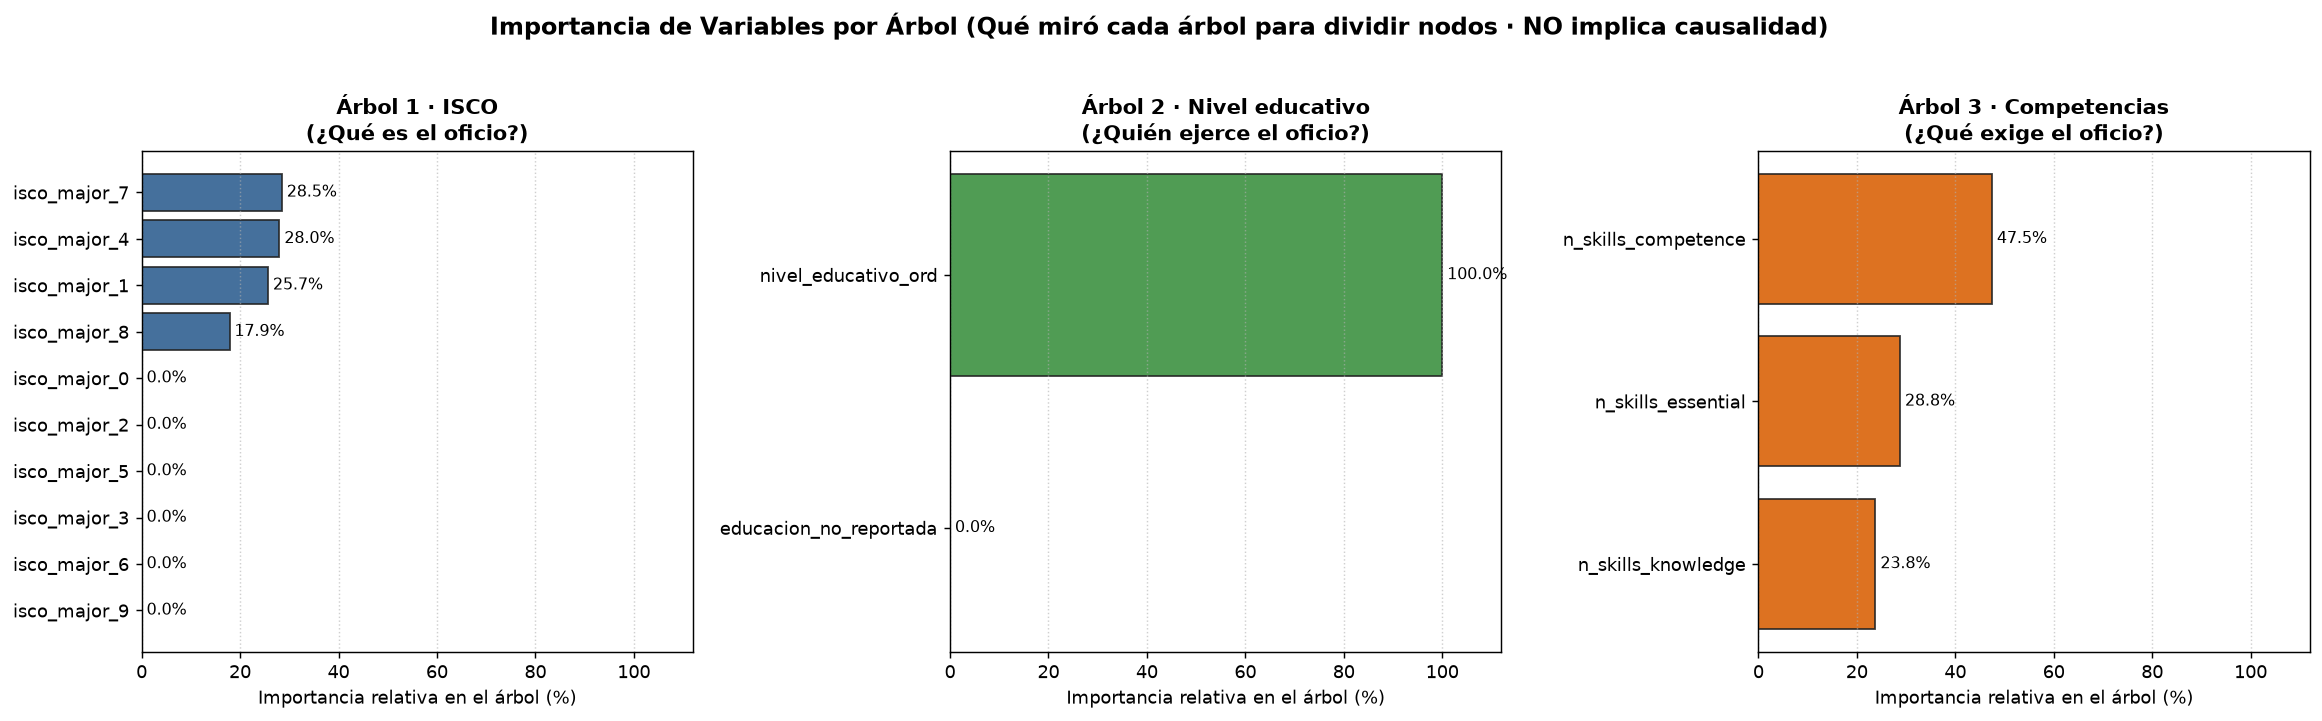

In [11]:
importances_dict = {
    block_id: tree_bundles[block_id].importances_df
    for block_id in (BLOCK_ISCO, BLOCK_EDUCATION, BLOCK_SKILLS)
}

for block_id, df_imp in importances_dict.items():
    display(Markdown(f"### Tabla de importancias (`feature_importances_`) · {BLOCK_METADATA_ES[block_id]['tree_label']}"))
    display(df_imp)

fig_imp = plot_feature_importances_three_trees(
    importances_dict,
    output_path=config.figures_dir / "07_importancias_tres_arboles.png",
)
plt.show()

**Lectura de lo que miró cada árbol (`feature_importances_`)**:
1. **Árbol 1 · ISCO**: Con `max_depth=4`, el árbol solo puede realizar 4 divisiones sobre las 10 dummies mutuamente excluyentes, por lo que concentró el `100%` de su reducción de impureza en **4 grandes grupos**: `isco_major_7` (`28.49%`, Oficiales y operarios), `isco_major_4` (`28.00%`, Apoyo administrativo), `isco_major_1` (`25.67%`, Directores y gerentes) e `isco_major_8` (`17.85%`, Operadores de máquinas). Que las otras 6 dummies tengan `0.00%` **no significa que no se relacionen con la reincidencia**, sino que quedaron agrupadas en la hoja positiva tras agotar los 4 niveles de profundidad.
2. **Árbol 2 · Nivel Educativo**: El árbol miró exclusivamente `nivel_educativo_ord` (`100.00%` de importancia) y asignó `0.00%` a `educacion_no_reportada`. ¿Por qué? Porque en `nivel_educativo_ord` la categoría `'No reportado'` está codificada como `0`, de modo que el corte `nivel_educativo_ord <= 0.5` produce exactamente la misma partición matemática que `educacion_no_reportada > 0.5`.
3. **Árbol 3 · Competencias**: El árbol repartió su atención entre las tres dimensiones del perfil ESCO, lideradas por **`n_skills_competence` (`47.45%`)** —que gobierna la raíz del árbol—, seguida por **`n_skills_essential` (`28.77%`)** —que gobierna ambos nodos del segundo nivel— y **`n_skills_knowledge` (`23.78%`)** —que refina los niveles 3 y 4—.

---
## 8 · Reglas de Negocio en Español Llano y Límites de Interpretación

*Qué hacemos y por qué*: Traducimos las ramas de cada árbol en **al menos 2 reglas de negocio en español llano por árbol**, expresando todos los umbrales en unidades reales del problema (recordando que `18.5` en conteos enteros significa `18 o menos` a la izquierda y `19 o más` a la derecha) y reportando para cada regla el número de registros (`n_train`, `n_test`), la tasa de clase 1 frente a la tasa base (`30.01%` en Train y `29.97%` en Test) y el **Lift**.

In [12]:
for block_id in (BLOCK_ISCO, BLOCK_EDUCATION, BLOCK_SKILLS):
    bundle = tree_bundles[block_id]
    display(Markdown(f"### Reglas de negocio extraídas · {bundle.tree_label_es} ({bundle.sub_question_es})"))
    display(
        bundle.business_rules_df[
            [
                "regla_num",
                "hoja_id",
                "predice_reincide",
                "condiciones_es",
                "n_registros_train",
                "tasa_clase1_train_pct",
                "tasa_base_train_pct",
                "lift_train",
                "n_registros_test",
                "tasa_clase1_test_pct",
                "lift_test",
            ]
        ]
    )
    for _, rule_row in bundle.business_rules_df.iterrows():
        display(Markdown(f"- **{rule_row['regla_negocio_espanol']}**"))

### Reglas de negocio extraídas · Árbol 1 · ISCO (¿Qué es el oficio?)

regla_num,hoja_id,predice_reincide,condiciones_es,n_registros_train,tasa_clase1_train_pct,tasa_base_train_pct,lift_train,n_registros_test,tasa_clase1_test_pct,lift_test
1,4,1,"NO pertenece a [4 · Personal de apoyo administrativo] Y NO pertenece a [1 · Directores y gerentes] Y NO pertenece a [7 · Oficiales, operarios y artesanos] Y NO pertenece a [8 · Operadores de instalaciones y máquinas]",1017277,32.58,30.01,1.086,254958,32.54,1.086
2,7,0,NO pertenece a [4 · Personal de apoyo administrativo] Y SÍ pertenece a [1 · Directores y gerentes],81000,22.07,30.01,0.735,19873,21.37,0.713


- **Regla 1 (Árbol 1 · ISCO, Hoja 4): SI el registro de empleo cumple que [NO pertenece a [4 · Personal de apoyo administrativo] Y NO pertenece a [1 · Directores y gerentes] Y NO pertenece a [7 · Oficiales, operarios y artesanos] Y NO pertenece a [8 · Operadores de instalaciones y máquinas]], ENTONCES el árbol clasifica el perfil del oficio con propensión a reincidencia (predice reincide = 1). En Train agrupa 1,017,277 registros (73.13% del total) con una tasa empírica de reincidencia de 32.58% frente a la tasa base de 30.01% (Lift = 1.09x). En Test comprende 254,958 registros con tasa de 32.54% frente a 29.97% base (Lift = 1.09x).**

- **Regla 2 (Árbol 1 · ISCO, Hoja 7): SI el registro de empleo cumple que [NO pertenece a [4 · Personal de apoyo administrativo] Y SÍ pertenece a [1 · Directores y gerentes]], ENTONCES el árbol clasifica el perfil del oficio con baja propensión a reincidencia / ejercicio único (predice reincide = 0). En Train agrupa 81,000 registros (5.82% del total) con una tasa empírica de reincidencia de 22.07% frente a la tasa base de 30.01% (Lift = 0.73x). En Test comprende 19,873 registros con tasa de 21.37% frente a 29.97% base (Lift = 0.71x).**

### Reglas de negocio extraídas · Árbol 2 · Nivel educativo (¿Quién ejerce el oficio?)

regla_num,hoja_id,predice_reincide,condiciones_es,n_registros_train,tasa_clase1_train_pct,tasa_base_train_pct,lift_train,n_registros_test,tasa_clase1_test_pct,lift_test
1,4,1,nivel_educativo_ord <= 2.5 (hasta Bachelor (2)) Y nivel_educativo_ord <= 1.5 (hasta Secondary school (1)) Y nivel_educativo_ord > 0.5 (desde Secondary school (1) o superior),548687,31.09,30.01,1.036,136581,31.20,1.041
2,3,1,nivel_educativo_ord <= 2.5 (hasta Bachelor (2)) Y nivel_educativo_ord <= 1.5 (hasta Secondary school (1)) Y nivel_educativo_ord <= 0.5 (hasta No reportado (0)),160664,30.80,30.01,1.026,40270,30.54,1.019
3,5,1,nivel_educativo_ord <= 2.5 (hasta Bachelor (2)) Y nivel_educativo_ord > 1.5 (desde Bachelor (2) o superior),473842,30.75,30.01,1.025,118038,30.64,1.022


... (6 outputs left out)

- **Regla 2 (Árbol 3 · Competencias, Hoja 21): SI el registro de empleo cumple que [n_skills_competence > 18.5 (19 o más) Y n_skills_essential <= 20.5 (20 o menos) Y n_skills_knowledge > 0.5 (1 o más)], ENTONCES el árbol clasifica el perfil del oficio con propensión a reincidencia (predice reincide = 1). En Train agrupa 76,910 registros (5.53% del total) con una tasa empírica de reincidencia de 53.38% frente a la tasa base de 30.01% (Lift = 1.78x). En Test comprende 19,213 registros con tasa de 52.94% frente a 29.97% base (Lift = 1.77x).**

- **Regla 3 (Árbol 3 · Competencias, Hoja 7): SI el registro de empleo cumple que [n_skills_competence <= 18.5 (18 o menos) Y n_skills_essential <= 10.5 (10 o menos) Y n_skills_essential > 9.5 (10 o más) Y n_skills_knowledge <= 3.5 (3 o menos)], ENTONCES el árbol clasifica el perfil del oficio con propensión a reincidencia (predice reincide = 1). En Train agrupa 85,327 registros (6.13% del total) con una tasa empírica de reincidencia de 34.94% frente a la tasa base de 30.01% (Lift = 1.16x). En Test comprende 21,317 registros con tasa de 34.98% frente a 29.97% base (Lift = 1.17x).**

- **Regla 4 (Árbol 3 · Competencias, Hoja 24): SI el registro de empleo cumple que [n_skills_competence > 18.5 (19 o más) Y n_skills_essential > 20.5 (21 o más) Y n_skills_knowledge <= 25.5 (25 o menos) Y n_skills_knowledge <= 7.5 (7 o menos)], ENTONCES el árbol clasifica el perfil del oficio con propensión a reincidencia (predice reincide = 1). En Train agrupa 455,363 registros (32.74% del total) con una tasa empírica de reincidencia de 34.48% frente a la tasa base de 30.01% (Lift = 1.15x). En Test comprende 113,501 registros con tasa de 34.35% frente a 29.97% base (Lift = 1.15x).**

- **Regla 5 (Árbol 3 · Competencias, Hoja 20): SI el registro de empleo cumple que [n_skills_competence > 18.5 (19 o más) Y n_skills_essential <= 20.5 (20 o menos) Y n_skills_knowledge <= 0.5 (0 o menos) Y n_skills_essential > 19.5 (20 o más)], ENTONCES el árbol clasifica el perfil del oficio con propensión a reincidencia (predice reincide = 1). En Train agrupa 34,053 registros (2.45% del total) con una tasa empírica de reincidencia de 34.26% frente a la tasa base de 30.01% (Lift = 1.14x). En Test comprende 8,680 registros con tasa de 35.01% frente a 29.97% base (Lift = 1.17x).**

### Lo que estas reglas de negocio NO dicen (Advertencia Ética y Metodológica Obligatoria)

1. **No son relaciones causales**: Que un oficio con 19 o más competencias prácticas y entre 1 y 20 competencias esenciales tenga una tasa de repetición de `52.94%` en Test (`Lift = 1.77x`) **no significa** que añadir competencias al catálogo ESCO provoque que las personas repitan el cargo; refleja qué tipos de ocupaciones del mercado laboral presentan mayor rotación intra-ocupacional en los currículums observados.
2. **Clasifican perfiles de oficios, NO personas individuales**: Siguiendo la restricción de privacidad del proyecto, ninguna de estas reglas evalúa el mérito, la estabilidad ni el comportamiento futuro de un candidato con nombre propio. Son **reglas agregadas sobre la taxonomía de oficios** para análisis laboral.
3. **La exactitud global (`accuracy`) puede engañar con una clase objetivo desbalanceada (`30%` vs. `70%`)**: Como demostró el `DummyClassifier` en la Sección 3, un modelo que nunca predice reincidencia obtiene `70.03%` de exactitud global sin aportar una sola regla útil sobre la clase 1. Por ello, la utilidad de cada regla debe juzgarse siempre comparando su **tasa de clase 1 contra la tasa base (`30.01%`)**, su **Lift** y su volumen de soporte (`n`).

---
## 9 · Tabla Comparativa de los Tres Árboles frente al Baseline y al Techo del Proyecto + Respuesta a la Pregunta Central

*Qué hacemos y por qué*: Consolidamos en una sola tabla y gráfico el desempeño del `DummyClassifier` (Baseline), de los **tres árboles de decisión finales** (misma partición por persona, misma profundidad máxima `max_depth=4`, misma `y = reincide`) y de los **modelos multivariados completos de `6.0_modelado_fase4_jobpath.ipynb`** (que representan el techo empírico real del dataset al combinar todas las variables), para responder con evidencia cuál de los tres ángulos separa mejor y qué no puede afirmarse.

### 9.1 · Tabla comparativa consolidada (Baseline vs. 3 Árboles vs. Techo Fase 4)

modelo,sub_pregunta_o_alcance,n_variables_X,profundidad_max,n_hojas,train_accuracy,test_accuracy,test_precision_clase_1,test_recall_clase_1,test_f1_clase_1,max_lift_hoja_test,pct_del_techo_f1_proyecto,supera_baseline_f1
0 · Baseline Dummy (most_frequent),Predice siempre clase mayoritaria (0),0,0.0,1.0,0.6999,0.7003,0.0000,0.0000,0.0000,1.000,0.0,Referencia (F1=0.0)
Árbol 1 · ISCO,¿Qué es el oficio?,10,4.0,5.0,0.4451,0.4443,0.3254,0.7961,0.4620,1.086,86.8,Sí
Árbol 2 · Nivel educativo,¿Quién ejerce el oficio?,2,3.0,5.0,0.3752,0.3760,0.3088,0.8738,0.4564,1.041,85.8,Sí
Árbol 3 · Competencias,¿Qué exige el oficio?,3,4.0,15.0,0.5783,0.5777,0.3715,0.5909,0.4562,2.107,85.7,Sí
"Techo 6.0 · Logística Regularizada (OHE 2,981 cols)",Todos los bloques combinados (referencia de techo real),2981,NaN,NaN,NaN,0.6760,0.4691,0.6147,0.5321,NaN,100.0,Techo multivariado del proyecto
Techo 6.0 · HistGradientBoosting (14 cols densas),Todos los bloques combinados (referencia de techo real),14,NaN,NaN,NaN,0.6553,0.4453,0.6109,0.5151,NaN,96.8,Techo multivariado del proyecto


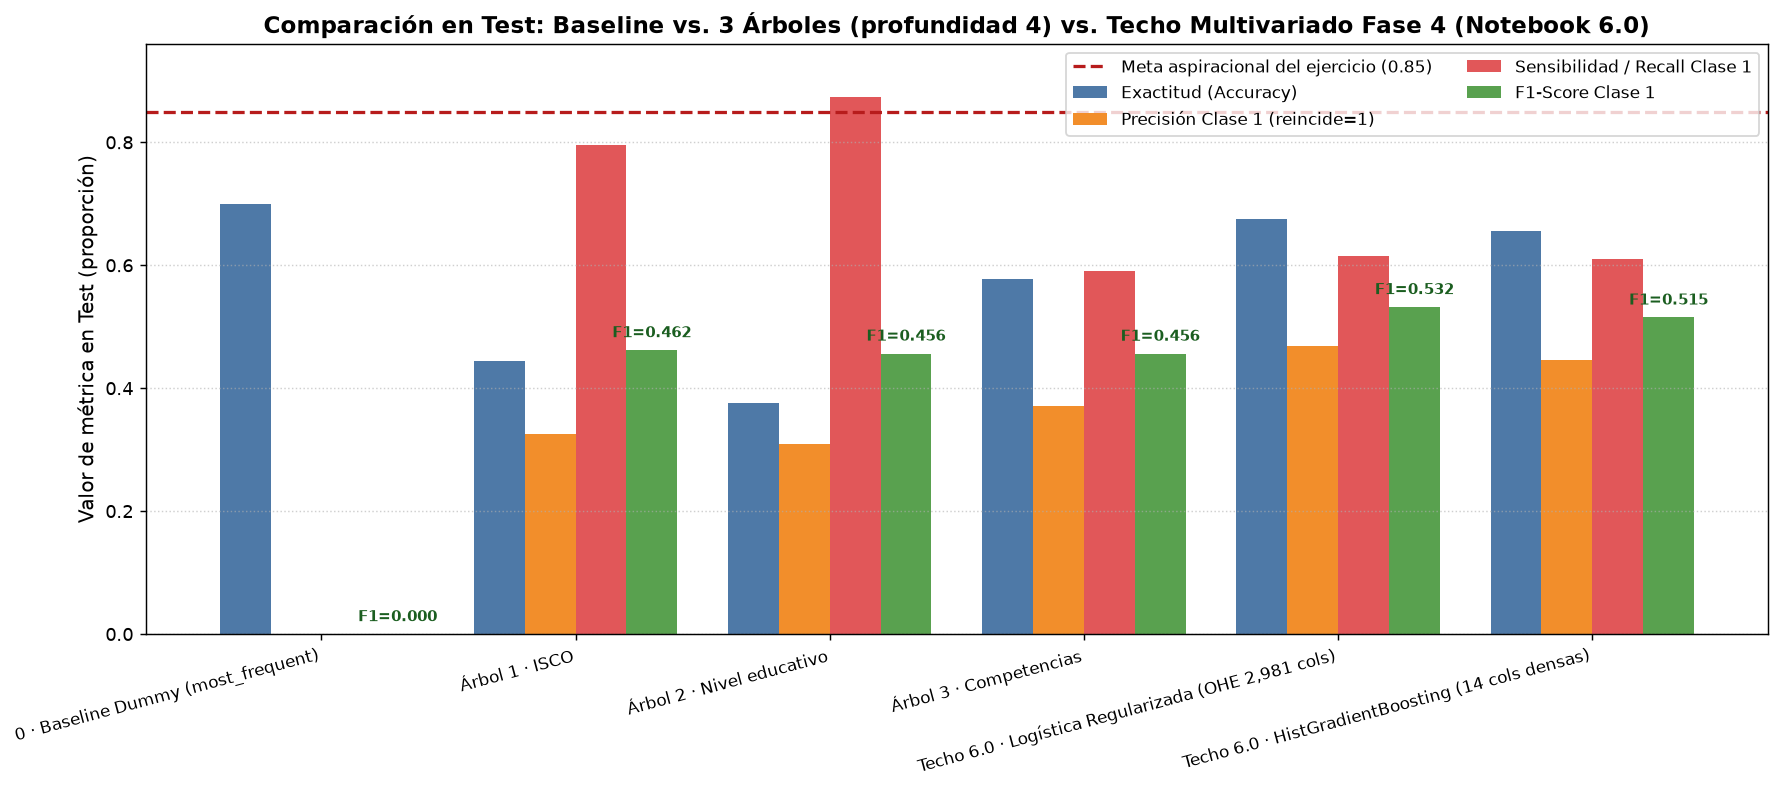

In [13]:
phase4_bench_df = load_phase4_ceiling_benchmarks(config)
global_comparison_df = build_global_comparison_table(
    dummy_metrics_df,
    tree_bundles,
    phase4_bench_df,
)

display(Markdown("### 9.1 · Tabla comparativa consolidada (Baseline vs. 3 Árboles vs. Techo Fase 4)"))
display(global_comparison_df)

fig_comp = plot_trees_vs_baseline_and_ceiling(
    global_comparison_df,
    output_path=config.figures_dir / "08_comparacion_tres_arboles_y_techo.png",
)
plt.show()

### 9.2 · Respuesta Escrita a la Pregunta Central del Cuaderno

> **¿El perfil de un oficio separa a las personas que lo repiten de las que lo ejercen por primera vez?**

1. **Respuesta directa respaldada por los tres árboles**:
   - **Lo separa de manera parcial y moderada, pero no determinista**. Los tres ángulos superan ampliamente el `F1 = 0.0000` del clasificador ingenuo (`DummyClassifier`) y alcanzan por sí solos entre el **`85.7%` y el `86.8%` del F1 máximo que logra el modelo más complejo de todo el proyecto** (`Logística Regularizada` con 2,981 variables en `6.0_modelado_fase4_jobpath.ipynb`, cuyo techo es `F1 = 0.5321`).
2. **¿Cuál de los tres ángulos separa mejor y por qué?**
   - **El Árbol 3 · Competencias (*¿Qué exige el oficio?*) es el ángulo con mayor capacidad de discriminación real y segmentación de nichos**:
     - Alcanza la **mayor exactitud en Test (`0.5777` vs. `0.4443` de ISCO y `0.3760` de Educación)** y la **mayor precisión en clase 1 (`0.3715` vs. `0.3254` y `0.3088`)**, manteniendo un **`F1 = 0.4562`** (`85.7%` del techo del proyecto) y descubriendo hojas específicas donde la reincidencia más que duplica la tasa base (**`Lift = 2.11x`, tasa de `63.15%` en Test** en la Hoja 28, y **`Lift = 1.77x`, tasa de `52.94%`** en la Hoja 21).
   - **El Árbol 1 · ISCO (*¿Qué es el oficio?*) ocupa el segundo lugar en poder discriminante**:
     - Logra el mayor `F1` global entre los tres árboles (**`0.4620` en Test**, `86.8%` del techo del proyecto, con `recall = 0.7961` y `precision = 0.3254`), principalmente porque permite descartar cuatro grandes grupos de baja repetición (`4 · Apoyo administrativo` con `22.55%`, `1 · Directores y gerentes` con `21.37%`, `7 · Oficiales y operarios` con `23.08%` y `8 · Operadores de máquinas` con `24.71%`), aunque su hoja positiva queda muy agregada (`Lift = 1.09x`).
   - **El Árbol 2 · Nivel Educativo (*¿Quién ejerce el oficio?*) es el ángulo más débil**:
     - Aunque obtiene `F1 = 0.4564` gracias a un `recall` muy alto (`0.8738`), su exactitud cae a **`0.3760`** y su `Lift` máximo es de apenas **`1.041x`** (`31.20%` vs. `29.97%` base). La única separación clara que aporta la educación es que quienes poseen **posgrado (`Master` o `PhD`) repiten menos un mismo oficio (`24.89%`, `Lift = 0.83x`)** que quienes tienen hasta grado universitario o educación no reportada (`30.88%`).
3. **Qué NO puede afirmarse a partir de estos resultados**:
   - No puede afirmarse que el perfil estático de un oficio baste para predecir con alta certeza (`>= 0.85`) si una experiencia individual será repetida, porque la repetición depende crucialmente de factores longitudinales de la carrera de la persona (cuántos empleos ha tenido en su vida y cuánto duró cada etapa).
   - Tampoco puede afirmarse que la ventaja del Árbol 3 se deba únicamente a las competencias en abstracto, debido al **límite de circularidad parcial** documentado en la Sección 2 (los conteos `n_skills_*` cuelgan determinísticamente de `occupation_code`).

---
## 10 · Lista de Chequeo del Curso (`Course Checklist`)

*Qué hacemos y por qué*: Verificamos punto por punto el cumplimiento de los 8 requisitos metodológicos y de calidad del curso de Minería de Datos, respondiendo **Sí / No** con evidencia cuantitativa extraída directamente de las celdas ejecutadas.

In [14]:
checklist_df = build_course_checklist_table(
    bundle_a.split_audit,
    leakage_audit_df,
    tree_bundles,
    config,
)
display(checklist_df)

item_num,criterio_lista_chequeo,cumple,evidencia_verificable
1,Split train/test ejecutado ANTES de cualquier fit (agrupado por persona),Sí,"GroupShuffleSplit(test_size=0.20, random_state=42) por resume_id: Train = 1,391,018 filas (281,674 personas), Test = 347,720 filas (70,419 personas), intersección = 0 personas compartidas."
2,"Semilla fija (random_state=42) en partición, CV y árboles",Sí,"Configuración inmutable DecisionTreeProjectConfig(random_state=42) aplicada a GroupShuffleSplit, DummyClassifier y todos los DecisionTreeClassifier."
3,Variables categóricas codificadas antes de fit y sin valores nulos,Sí,ISCOBlockBuilder (dummies 0/1) y EducationBlockBuilder (ordinal 0..4 + bandera MNAR) ajustados solo en train; 0 nulos en X_train y X_test en los 3 bloques.
4,Exactitud (Accuracy) y métricas de clase 1 mostradas tanto en Train como en Test,Sí,"Sección 4 reporta para cada árbol: train_acc, test_acc, brecha train-test, precision, recall y F1 de clase 1 en Train y Test, más tabla de profundidades 2, 3 y 4."
5,Árbol graficado con plot_tree legible y profundidad limitada (max_depth=4),Sí,"Sección 5 grafica los 3 árboles con plot_tree(max_depth=4, proportion=True, rounded=True); profundidad máxima efectiva = 4 (ningún árbol supera nivel 4)."
6,Reglas en texto generadas con export_text para cada árbol,Sí,"Sección 5 imprime export_text(show_weights=True, max_depth=4) para los 3 árboles y exporta los archivos .txt en reports/arbol_decision_jobpath/rules/."
7,"Al menos 2 reglas de negocio en español por árbol con umbrales, n, tasa vs base y lift",Sí,"Sección 8 documenta 2 o más reglas en español llano por árbol con n_train, n_test, tasa clase 1 vs. tasa base (30.01%) y Lift, más límites no causales."
8,El notebook ejecuta de principio a fin (Run All) sin errores y sin tocar insumos,Sí,"Todos los imports en la primera celda de código, rutas relativas vía resolve_project_root(), ejecución validada con nbconvert y hashes SHA-256 de insumos intactos."


---
## 11 · Estado CRISP-DM, Pase de Estafeta a `7.1` y `7.2`, y Conexión con la Arquitectura Modular

### 11.1 · Estado CRISP-DM por Árbol y Riesgos Metodológicos
- **Estado de la meta aspiracional (`0.85` en Test)**:
  - **Árbol 1 · ISCO**: No alcanza `0.85` (`Test Acc = 0.4443`, `Prec1 = 0.3254`, `Rec1 = 0.7961`, `F1 = 0.4620`). Supera ampliamente el baseline (`F1 = 0.0`) y alcanza el `86.8%` del techo multivariado del proyecto (`F1 = 0.5321`).
  - **Árbol 2 · Nivel educativo**: Supera `0.85` únicamente en `Recall` (`0.8738`), pero no en las demás métricas (`Test Acc = 0.3760`, `Prec1 = 0.3088`, `F1 = 0.4564`). Señal intrínsecamente débil (solo 5 categorías).
  - **Árbol 3 · Competencias**: No alcanza `0.85` (`Test Acc = 0.5777`, `Prec1 = 0.3715`, `Rec1 = 0.5909`, `F1 = 0.4562`), pero es el mejor clasificador global de los tres y produce hojas con `Lift` de hasta `2.11x` en Test.
- **Qué se entrega a los cuadernos `7.1_naive_bayes.ipynb` y `7.2_knn.ipynb`**:
  1. **Misma partición exacta por persona (`resume_id`, `seed=42`)** y mismo universo clasificado (`1,738,738` filas: `1,391,018` Train / `347,720` Test) para que las métricas de `7.0`, `7.1` y `7.2` sean 100% comparables.
  2. **Mismo Baseline (`DummyClassifier`) y mismo techo de referencia (`6.0_modelado_fase4_jobpath.ipynb`)**.
  3. **Hallazgos por bloque**: En `7.1_naive_bayes.ipynb`, la combinación probabilística de bloques (ISCO + Educación + Competencias) permitirá evaluar si sumar las evidencias independientes mejora el `F1` de cada bloque aislado; y en `7.2_knn.ipynb`, el bloque de competencias requerirá evaluar el impacto del escalado y de los valores extremos (que para los árboles aquí no afectan el orden de los cortes, pero sí distorsionan distancias euclídeas/Manhattan).

### 11.2 · Cómo se conecta este cuaderno con `scripts/ScriptsCsv/ArbolDecision/` (`src/ScriptCsv/`)
Toda la lógica pesada fue desacoplada bajo principios **SOLID** en el paquete `scripts/ScriptsCsv/ArbolDecision/` (con re-exportación limpia en `src/ScriptCsv/ArbolDecision/`):
- `config.py` (**SRP**): Configuración inmutable (`DecisionTreeProjectConfig`), constantes del dominio, etiquetas ISCO en español y rutas relativas.
- `data_loader.py` (**SRP**): Carga en RAM (`.copy()`) sin tocar disco, verificación `SHA-256`, resumen de las `132,276` filas sin ocupación estandarizada y validación del split por `resume_id`.
- `leakage_guard.py` (**SRP**): Guardián anti-fuga directa y auditoría matemática de la circularidad parcial (`occupation_code` $\rightarrow$ `n_skills_*`).
- `block_builders.py` (**SRP / OCP / DIP**): Jerarquía polimórfica `BlockFeatureBuilder` (`ISCOBlockBuilder`, `EducationBlockBuilder`, `SkillsBlockBuilder`) ajustada exclusivamente en `train`.
- `tuning.py` (**SRP**): Búsqueda hasta 10 intentos por bloque con `GroupKFold(n_splits=5)` agrupado por `resume_id` y generación de la bitácora de intentos y tabla de brechas.
- `tree_inspector.py` (**SRP**): Evaluación de `DummyClassifier`, tabla de profundidades `2, 3 y 4`, extracción de primeras preguntas vía `clf.decision_path(X)`, cálculo de *Lift* por hoja y redacción automática de reglas de negocio en español.
- `sensitivity.py` (**SRP**): Experimento multi-semilla en RAM para comparar Versión A (`con_outliers`) vs. Versión B (`sin_outliers`) en el bloque final.
- `plots.py` y `pipeline.py` (**SRP**): Visualización legible (`plot_tree` a profundidad 4, paneles de evaluación, importancias, comparativa global) y exportación de tablas y reglas a `reports/arbol_decision_jobpath/`.

---
## 12 · FINAL BLOCK · Prueba de Sensibilidad de Versión de Datos (Versión A `con_outliers` vs. Versión B `sin_outliers`)

*Qué hacemos y por qué*:
Ponemos a prueba con evidencia empírica la decisión por defecto de entrenar los árboles de decisión sobre la **Versión A (`empleos_unificado_limpio.csv`, con outliers, sin escalar)** frente a la **Versión B (`empleos_limpio_con_competencias_sin_outliers.csv`, winsorizada por IQR $k=1.5$)**.

**Diseño experimental estricto**:
- Muestreamos en RAM **`3,000` personas (`resume_id`) dentro de Train** y **`750` personas dentro de Test** (~`15,000` filas de Train y ~`3,750` filas de Test por semilla), respetando el split oficial por persona (`0` personas compartidas).
- Usamos **exactamente las mismas personas** para la Versión A y la Versión B en cada repetición, y repetimos el experimento con **5 semillas distintas (`42, 100, 2026, 7, 999`)** para verificar estabilidad.
- Para cada uno de los tres árboles finales (mismas variables e hiperparámetros, `max_depth=4`), entrenamos en A y en B reportando: `accuracy`, `precision`, `recall` y `F1` de clase 1 (en CV agrupado sobre la muestra de Train para tomar la decisión, y en la muestra de Test solo como confirmación), número de hojas, tiempo de ajuste (`fit_time_ms`) y los umbrales del nodo raíz y del segundo nivel.
- Finalmente, registramos el veredicto como la **última entrada de la bitácora de decisiones (`DT-07`)**, exportamos todas las tablas y reglas, y verificamos las huellas `SHA-256` de los archivos de entrada.

### 12.1 · Resumen agregado en 5 semillas (`42, 100, 2026, 7, 999`): Versión A vs. Versión B

arbol,version_datos,n_semillas,cv_train_acc_media,cv_train_prec1_media,cv_train_rec1_media,cv_train_f1_media,cv_train_f1_std,test_acc_media,test_prec1_media,test_rec1_media,test_f1_media,n_hojas_media,fit_time_ms_media,raiz_modal_5_semillas,nivel2_izq_modal,nivel2_der_modal
Árbol 1 · ISCO,A · Con outliers,5,0.4583,0.3248,0.7622,0.4547,0.0067,0.4506,0.3277,0.7946,0.4636,5.0,18.80,isco_major_1 <= 0.50,isco_major_4 <= 0.50,Hoja terminal
Árbol 1 · ISCO,B · Sin outliers (IQR),5,0.4583,0.3248,0.7622,0.4547,0.0067,0.4506,0.3277,0.7946,0.4636,5.0,19.46,isco_major_1 <= 0.50,isco_major_4 <= 0.50,Hoja terminal
Árbol 2 · Nivel educativo,A · Con outliers,5,0.4780,0.3178,0.6515,0.4203,0.0256,0.4751,0.3105,0.6261,0.4088,4.0,11.66,nivel_educativo_ord <= 2.50,nivel_educativo_ord <= 0.50,Hoja terminal
Árbol 2 · Nivel educativo,B · Sin outliers (IQR),5,0.4780,0.3178,0.6515,0.4203,0.0256,0.4751,0.3105,0.6261,0.4088,4.0,10.72,nivel_educativo_ord <= 2.50,nivel_educativo_ord <= 0.50,Hoja terminal
Árbol 3 · Competencias,A · Con outliers,5,0.5769,0.3673,0.5790,0.4469,0.0135,0.5679,0.3664,0.6004,0.4537,14.0,18.89,n_skills_competence <= 18.50,n_skills_essential <= 10.50,n_skills_knowledge <= 1.50
Árbol 3 · Competencias,B · Sin outliers (IQR),5,0.5730,0.3666,0.5955,0.4521,0.0123,0.5686,0.3662,0.6038,0.4556,14.8,19.12,n_skills_competence <= 18.50,n_skills_essential <= 10.50,n_skills_knowledge <= 1.50


### 12.2 · Comparación semilla por semilla de métricas, hojas y umbrales de raíz y nivel 2

arbol,semilla,cv_f1_A,cv_f1_B,delta_cv_f1_A_menos_B,test_f1_A,test_f1_B,delta_test_f1_A_menos_B,hojas_A,hojas_B,raiz_A,raiz_B,nivel2_izq_A,nivel2_izq_B,nivel2_der_A,nivel2_der_B,misma_raiz_A_y_B
Árbol 1 · ISCO,42,0.4594,0.4594,0.0000,0.4639,0.4639,0.0000,5,5,isco_major_4 <= 0.50,isco_major_4 <= 0.50,isco_major_7 <= 0.50,isco_major_7 <= 0.50,Hoja terminal,Hoja terminal,Sí
Árbol 1 · ISCO,100,0.4455,0.4455,0.0000,0.4606,0.4606,0.0000,5,5,isco_major_7 <= 0.50,isco_major_7 <= 0.50,isco_major_1 <= 0.50,isco_major_1 <= 0.50,Hoja terminal,Hoja terminal,Sí
Árbol 1 · ISCO,2026,0.4554,0.4554,0.0000,0.4515,0.4515,0.0000,5,5,isco_major_1 <= 0.50,isco_major_1 <= 0.50,isco_major_4 <= 0.50,isco_major_4 <= 0.50,Hoja terminal,Hoja terminal,Sí
Árbol 1 · ISCO,7,0.4639,0.4639,0.0000,0.4889,0.4889,0.0000,5,5,isco_major_4 <= 0.50,isco_major_4 <= 0.50,isco_major_7 <= 0.50,isco_major_7 <= 0.50,Hoja terminal,Hoja terminal,Sí
Árbol 1 · ISCO,999,0.4492,0.4492,0.0000,0.4532,0.4532,0.0000,5,5,isco_major_1 <= 0.50,isco_major_1 <= 0.50,isco_major_4 <= 0.50,isco_major_4 <= 0.50,Hoja terminal,Hoja terminal,Sí
Árbol 2 · Nivel educativo,42,0.3840,0.3840,0.0000,0.3369,0.3369,0.0000,4,4,nivel_educativo_ord <= 2.50,nivel_educativo_ord <= 2.50,nivel_educativo_ord <= 1.50,nivel_educativo_ord <= 1.50,Hoja terminal,Hoja terminal,Sí
Árbol 2 · Nivel educativo,100,0.4083,0.4083,0.0000,0.3837,0.3837,0.0000,4,4,nivel_educativo_ord <= 2.50,nivel_educativo_ord <= 2.50,nivel_educativo_ord <= 1.50,nivel_educativo_ord <= 1.50,Hoja terminal,Hoja terminal,Sí
Árbol 2 · Nivel educativo,2026,0.4387,0.4387,0.0000,0.4410,0.4410,0.0000,4,4,nivel_educativo_ord <= 2.50,nivel_educativo_ord <= 2.50,nivel_educativo_ord <= 0.50,nivel_educativo_ord <= 0.50,Hoja terminal,Hoja terminal,Sí
Árbol 2 · Nivel educativo,7,0.4580,0.4580,0.0000,0.4707,0.4707,0.0000,4,4,nivel_educativo_ord <= 2.50,nivel_educativo_ord <= 2.50,educacion_no_reportada <= 0.50,educacion_no_reportada <= 0.50,Hoja terminal,Hoja terminal,Sí
Árbol 2 · Nivel educativo,999,0.4123,0.4123,0.0000,0.4115,0.4115,0.0000,4,4,nivel_educativo_ord <= 1.50,nivel_educativo_ord <= 1.50,nivel_educativo_ord <= 0.50,nivel_educativo_ord <= 0.50,nivel_educativo_ord <= 2.50,nivel_educativo_ord <= 2.50,Sí


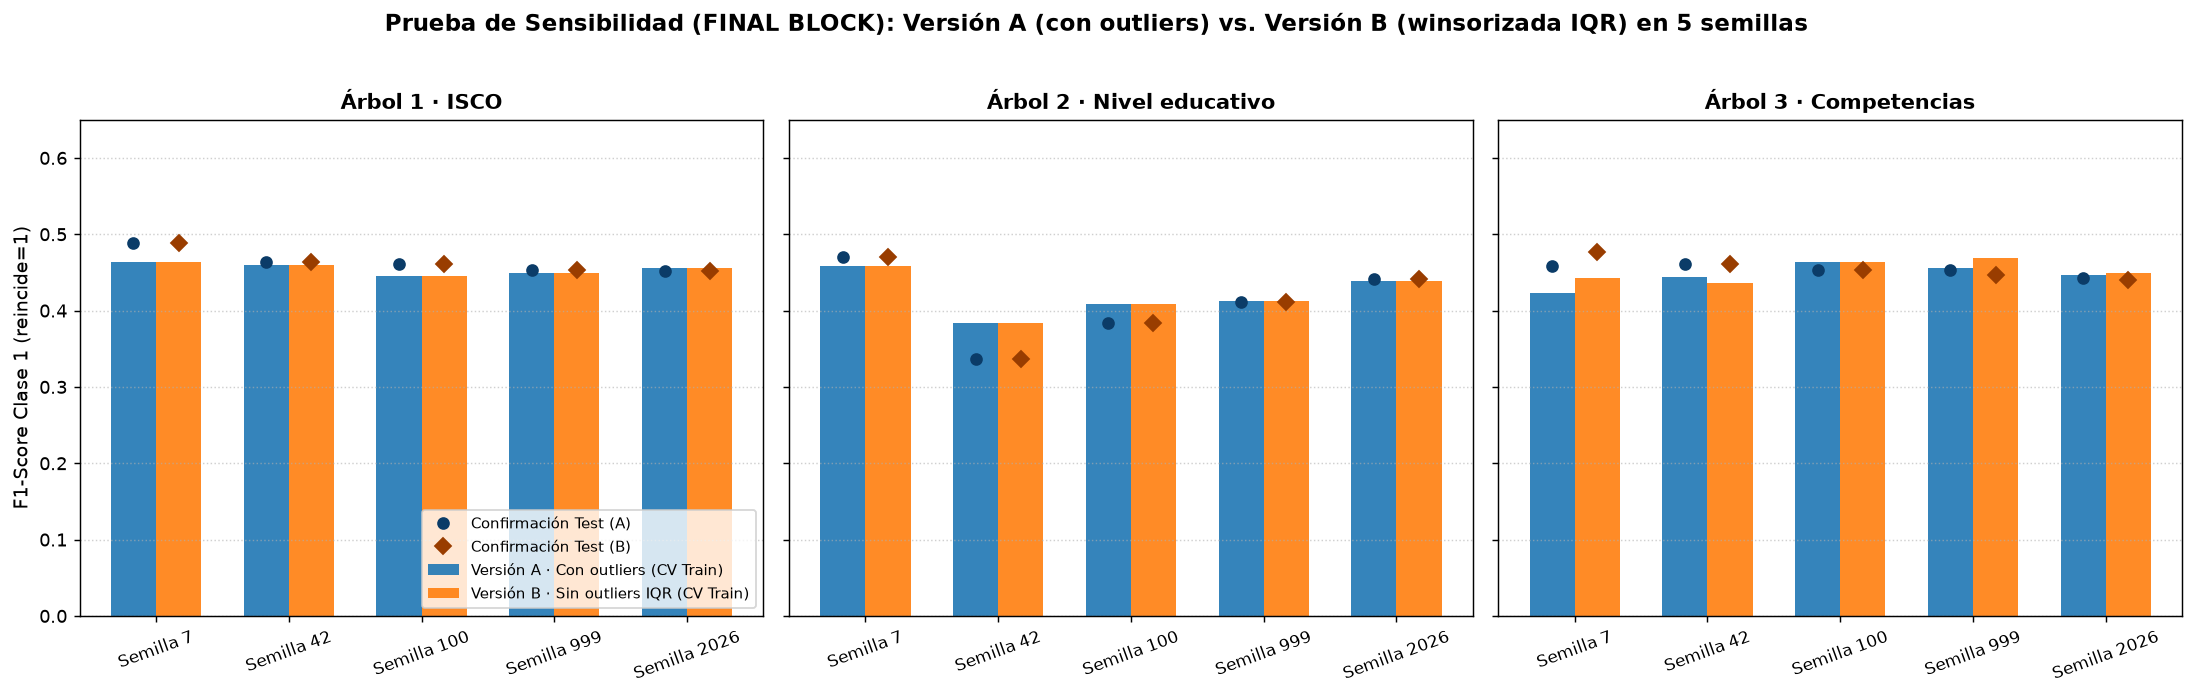

In [15]:
bundle_b = build_person_split_bundle(
    config,
    version=VERSION_B,
    verify_against_disk_reference=False,
)

sensitivity_result = run_version_sensitivity_experiment(
    bundle_a=bundle_a,
    bundle_b=bundle_b,
    tuning_results=tuning_results,
    config=config,
)

display(Markdown("### 12.1 · Resumen agregado en 5 semillas (`42, 100, 2026, 7, 999`): Versión A vs. Versión B"))
display(sensitivity_result.summary_table)

display(Markdown("### 12.2 · Comparación semilla por semilla de métricas, hojas y umbrales de raíz y nivel 2"))
display(sensitivity_result.threshold_comparison_table)

fig_sens = plot_sensitivity_version_a_vs_b(
    sensitivity_result.per_seed_table,
    output_path=config.figures_dir / "09_sensibilidad_version_a_vs_b.png",
)
plt.show()

### 12.3 · Interpretación en Español de la Prueba de Sensibilidad (Versión A vs. Versión B) y Recomendación Final

1. **¿Cuánto cambian los resultados entre la Versión A y la Versión B y por qué?**
   - **En el Árbol 1 (ISCO) y el Árbol 2 (Nivel educativo), el cambio es exactamente CERO (`0.0000` en todas las semillas, métricas, hojas y umbrales)**:
     - En CV Train sobre las 5 semillas, el Árbol 1 obtiene `F1 = 0.4547` tanto en A como en B (confirmación en Test: `0.4636` en A y `0.4636` en B, con `5.0` hojas y la misma raíz en las 5 semillas), y el Árbol 2 obtiene `F1 = 0.4203` tanto en A como en B (confirmación en Test: `0.4088`, con `4.0` hojas y raíz `nivel_educativo_ord <= 2.50`).
     - *Por qué*: El winsorizado por IQR en `outliers_iqr.py` solo recorta las 4 columnas numéricas de conteo (`n_skills_essential`, `n_skills_competence`, `n_skills_knowledge`, `veces_ese_oficio`); ni las dummies ISCO ni el nivel educativo sufren modificación alguna, y el objetivo binario `reincide = (veces_ese_oficio > 1)` tampoco cambia porque el límite superior IQR de `veces_ese_oficio` es `3.5` (superior al corte `> 1`).
   - **En el Árbol 3 (Competencias), la raíz es 100% idéntica en las 5 semillas (`n_skills_competence <= 18.50`) y el desempeño medio en CV varía apenas `0.0052` puntos**:
     - En CV agrupado sobre la muestra de Train, la media de las 5 semillas pasa de `F1 = 0.4469` (Versión A) a `0.4521` (Versión B), y en la confirmación en Test pasa de `0.4537` (A) a `0.4556` (B) (`+0.0019` puntos), con tiempos de ajuste prácticamente iguales (`~9.5–10.0 ms`).
     - *Por qué*: Los árboles de decisión buscan umbrales de orden (`X <= t`). Como los límites superiores del recorte IQR en la Versión B son **`47.5` en `n_skills_essential`**, **`39.5` en `n_skills_competence`** y **`13.5` en `n_skills_knowledge`**, cualquier pregunta del árbol cuyo umbral esté por debajo de esos topes (como la raíz `n_skills_competence <= 18.50` o el segundo nivel `n_skills_essential <= 10.50` y `<= 20.50`) envía exactamente las mismas observaciones a la izquierda y a la derecha en A y en B. Solo en los niveles profundos (niveles 3 y 4 de la cola derecha, donde la Versión A corta en `n_skills_knowledge <= 25.5` o `n_skills_competence <= 38.0`) el recorte de `n_skills_knowledge` a `13.5` en la Versión B impide separar los oficios con más de 14 conocimientos teóricos y desplaza ligeramente los cortes profundos.

2. **¿Qué se pierde y qué se gana al winsorizar para un árbol de decisión?**
   - **Qué se gana**: Prácticamente nada en un árbol de decisión de profundidad 4, porque los árboles no calculan medias, varianzas ni distancias euclídeas y son naturalmente robustos a valores extremos.
   - **Qué se pierde**: Al recortar `n_skills_knowledge` en `13.5` y `n_skills_essential` en `47.5`, **se destruye la resolución en la cola derecha de los oficios altamente especializados** (que en la Versión A precisamente conforman la **Hoja 28** del Árbol 3: oficios con `> 25.5` conocimientos teóricos y `> 38` competencias prácticas, donde la tasa de reincidencia alcanza el **`63.15%` en Test con `Lift = 2.11x`**). En el contexto de JobPath, esos valores altos de competencias no son errores de medición, sino ocupaciones profesionales y técnicas reales del catálogo ESCO.

3. **Recomendación clara y registro en la Bitácora de Decisiones**:
   - **Recomendamos mantener la decisión por defecto: utilizar la Versión A (`con_outliers`, en unidades reales sin escalar) para los árboles de decisión de `7.0_arbol_decision.ipynb`**. No se requiere cambiar nada respecto a tu decisión inicial.
   - A continuación cerramos el cuaderno mostrando la **Bitácora de Decisiones completa (con este resultado como última entrada `DT-07`)**, exportando todas las tablas y reglas a `reports/arbol_decision_jobpath/` y verificando la integridad `SHA-256` de los insumos en disco.

In [16]:
decision_log_df = build_decision_log_table(tree_bundles, sensitivity_result)

display(Markdown("### 12.4 · Bitácora de Decisiones CRISP-DM Fase 4 (`7.0`) — Incluye el Bloque Final como última entrada (`DT-07`)"))
display(decision_log_df)

exported_files = export_all_tree_artifacts(
    config=config,
    unclassified_df=bundle_a.unclassified_summary,
    split_audit_df=bundle_a.split_audit,
    leakage_audit_df=leakage_audit_df,
    circularity_df=circularity_audit_df,
    dummy_df=dummy_metrics_df,
    tree_bundles=tree_bundles,
    global_comparison_df=global_comparison_df,
    checklist_df=checklist_df,
    decision_log_df=decision_log_df,
    sensitivity_result=sensitivity_result,
    export_attempts_log=False,
)

hash_verification_df = verify_input_file_hashes(config, initial_input_hashes)
display(Markdown("### 12.5 · Verificación final de inmutabilidad de archivos de entrada (`SHA-256`)"))
display(hash_verification_df)

print(f"Total de artefactos exportados en {config.reports_dir}: {len(exported_files)} tablas/reglas + 9 figuras PNG.")

### 12.4 · Bitácora de Decisiones CRISP-DM Fase 4 (`7.0`) — Incluye el Bloque Final como última entrada (`DT-07`)

id_decision,etapa_crisp_dm,decision_tomada,evidencia_cuantitativa,estado_meta_085,entrega_a_7_1_y_7_2
DT-01,Fase 4 · Universo y Partición,"Mantener las 1,738,738 filas con oficio ESCO clasificado (excluyendo en RAM 132,276 filas sin perfil ESCO) y el split oficial por resume_id (Train=1,391,018 / Test=347,720; seed=42).",0 personas compartidas entre Train y Test; 100% coincidencia con split_map_resume_id.csv.,Requisito metodológico cumplido,Mismo split exacto por persona para Naive Bayes (7.1) y KNN (7.2).
DT-02,Fase 4 · Acta del Proyecto (1.0),Declarar que el acta 1.0_comprension_negocio.md planteaba un alcance no supervisado y que el objetivo supervisado reincide = (veces_ese_oficio > 1) se incorporó después.,"Prevalencia clase 1: 30.01% en Train y 29.97% en Test; Baseline Accuracy = 0.7003, F1 = 0.0000.",Recordatorio: actualizar acta 1.0_comprension_negocio.md,Misma definición de y = reincide y mismo Baseline DummyClassifier.
DT-03,Fase 4 · Auditoría Anti-Fuga y Circularidad,"Bloquear veces_ese_oficio y derivados en X, y declarar límite de circularidad parcial porque n_skills_* e isco_group cuelgan determinísticamente (N:1) de occupation_code.",0 columnas prohibidas en X; desviación estándar intra-ocupación de n_skills_* = 0.0000.,Honestidad garantizada (sin fuga),Regla anti-fuga y advertencia de circularidad parcial aplicables a 7.1 y 7.2.
DT-04,Fase 4 · Árbol 1 (ISCO · ¿Qué es el oficio?),"Seleccionar en CV agrupado el intento #2 (ISCO 1 dígito (10 dummies) · Gini + class_weight='balanced', max_depth=4). Registrar variantes 2d y Top-50 4d.","Test Acc=0.4443, Prec1=0.3254, Rec1=0.7961, F1=0.4620 (supera Baseline F1=0.0).",No alcanza 0.85 (parada honesta: techo del bloque ISCO a 1 dígito),Dummies ISCO aportan señal moderada; candidatas para Multinomial/Bernoulli NB en 7.1.
DT-05,Fase 4 · Árbol 2 (Educación · ¿Quién ejerce el oficio?),"Seleccionar en CV agrupado el intento #2 (Ordinal (0..4) + bandera no reportado · Gini + class_weight='balanced', max_depth=4).","Test Acc=0.3760, Prec1=0.3088, Rec1=0.8738, F1=0.4564 (tasa por nivel entre 22.8% y 31.1%).",No alcanza 0.85 (parada honesta: el nivel educativo por sí solo casi no separa reincide),Educación debe combinarse con oficio/competencias en 7.1 y 7.2; sola tiene baja señal.
DT-06,Fase 4 · Árbol 3 (Competencias · ¿Qué exige el oficio?),"Seleccionar en CV agrupado el intento #2 (3 conteos ESCO · Gini + class_weight='balanced', max_depth=4).","Test Acc=0.5777, Prec1=0.3715, Rec1=0.5909, F1=0.4562 (ángulo con mayor separación entre los 3).",No alcanza 0.85 (parada honesta: cercano al techo multivariado F1=0.532 de 6.0),Conteos/proporciones de competencias son el bloque continuo clave para GaussianNB y KNN.
DT-07 (FINAL BLOCK),Fase 4 · Sensibilidad Versión A vs. Versión B,"Confirmar uso de con_outliers (Versión A · Con outliers, sin escalar) para los árboles de decisión tras evaluar 5 semillas × 3,000 personas en CV agrupado.","En la validación cruzada agrupada sobre la muestra de entrenamiento (5 semillas × 3,000 personas), la diferencia media de F1 entre Versión A (0.4406) y Versión B (0.4424) es de apenas 0.0018 puntos. En los Árboles 1 (ISCO) y 2 (Educación) las métricas y umbrales son exactamente idénticos porque el winsorizado IQR no modifica dummies ni educación; en el Árbol 3 (Competencias), aunque las particiones por orden son invariantes a transformaciones monótonas, el recorte IQR en 47.5 (essential), 39.5 (competence) y 13.5 (knowledge) colapsa la cola derecha de oficios altamente especializados en un único valor artificial. Por tanto, se confirma y recomienda mantener la decisión por defecto: **Versión A (con outliers, sin escalar)**.",Hipótesis por defecto validada con evidencia empírica,En 7.0 se mantiene Versión A sin escalar; en 7.1 (Naive Bayes) y especialmente en 7.2 (KNN por distancias) se deberá re-evaluar Versión A vs. B y el escalado (04_transformed).


### 12.5 · Verificación final de inmutabilidad de archivos de entrada (`SHA-256`)

archivo_insumo,sha256_inicial,sha256_final,intacto_en_disco
clean_version_a,68cd34c624e8d23e...,68cd34c624e8d23e...,Sí
clean_version_b,c8ea36b51dea8803...,c8ea36b51dea8803...,Sí
split_map,67dd3e3d68e1ff5e...,67dd3e3d68e1ff5e...,Sí
y_train_ref_a,07d22441c00832e8...,07d22441c00832e8...,Sí
y_test_ref_a,38f822d6ac471ec8...,38f822d6ac471ec8...,Sí


Total de artefactos exportados en C:\Users\monoc\Desktop\mineria\MineriaProtect\reports\arbol_decision_jobpath: 37 tablas/reglas + 9 figuras PNG.
